# Phase I · Key findings of the human-only pair (TorchXRayVision `densenet121-res224-chex`)

Black-box analysis of a chest X-ray classifier that was trained only on CheXpert. Main question: **what drives the
false alarms (FP) and the misses (FN)?**

Two test sets:
- **NIH Google relabels**: 4,376 NIH images from another hospital, radiologist labels for Lung Opacity, Pneumothorax
  and Fracture.
- **CheXpert held-out**: ≈ 5,800 PA images from the model's own hospital that it did not train on, text-mined labels
  for all 11 outputs.

| Section | Key finding (last full run) |
|---|---|
| 2 · Baseline | Some findings are diagnosed badly. NIH: Fracture raises 79 % false alarms, Pneumothorax misses 58 %. CheXpert: Enlarged Cardiomediastinum misses about half |
| 3 · Outputs rise together | The 11 scores move together: each score follows the average of the other 10 (r ≈ 0.95). A false alarm rarely comes alone. The model judges "looks sick" more than single findings |
| 4 · Subgroups | Age and view change the errors most, sex only for a few outputs. The older the patient, the more false alarms and the fewer misses |
| 5 · Age on healthy images | Even when nothing is present, the overall level rises with age (CheXpert +0.05 per 10 years). The model reads age as sickness |
| 6 · Image properties | Contrast, sharpness and brightness go with the level only weakly and gradually, there is no clear cutoff. Exception: one NIH scanner (0.194 mm pixel spacing) with very flat images, where healthy images get ≈ 10 of 11 yes |
| 7 · Contrast perturbation | Causal check on that scanner: more contrast removes the false alarms, less contrast on other scanners creates them |
| 8 · Augmentations | Less contrast and blur raise the false alarms of most outputs (opacity-based group). Pneumothorax reacts the other way (misses more, fine edges). Sharpening hits Consolidation, Effusion, Pneumothorax. Warping raises all outputs evenly |

**Before running on Kaggle:**
1. *Add Input* → **Datasets** → **"NIH Chest X-rays"** (`nih-chest-xrays/data`) and **"CheXpert-v1.0-small"** (`ashery/chexpert`).
2. *Settings* → **Internet: On** (for `pip` and the model weights). Accelerator: **GPU T4**.
3. *Run all*. Full run ≈ 1 hour, most of it section 8. For a quicker run set `N_IMAGES = 2000` in section 8.

**Outputs** in `/kaggle/working/`: `predictions_chex.csv`, `predictions_chexpert_heldout.csv` (one row per image),
`run_info.json`, and `figures.zip` (every figure and table of sections 2–8).

In [1]:
import os, sys
try:
    import torchxrayvision
    print("torchxrayvision", torchxrayvision.__version__, "found in", sys.executable)
except ImportError:
    if os.path.exists("/kaggle"):
        # pinned to the commit we inspected (v1.5.7, 17.10.2026). Needs Settings -> Internet: On
        %pip install -q "git+https://github.com/mlmed/torchxrayvision@17726dd8f5e756eec3e5ae958281a289b05b1dae"
        import torchxrayvision
        print("installed torchxrayvision", torchxrayvision.__version__)
    else:
        raise ImportError(f"torchxrayvision is not installed for this kernel ({sys.executable}). "
                          "Locally: select the project's .venv kernel (VS Code: top right -> Select Kernel).")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.
installed torchxrayvision 1.5.7


## Config

In [2]:
import os
ON_KAGGLE = os.path.exists("/kaggle")
# Kaggle: full run. Locally (from shared/): the sample in data/kaggle_input_sample
INPUT_ROOT  = "/kaggle/input"   if ON_KAGGLE else os.path.abspath("../data/kaggle_input_sample")
WORK        = "/kaggle/working" if ON_KAGGLE else os.path.abspath("../data/local_run")
FIG_DIR     = os.path.join(WORK, "figures")                # every figure and table of sections 2–8, zipped at the end
LIMIT       = None              if ON_KAGGLE else 100     # None = all 4,376 NIH images
LINK_DIR    = os.path.join("/tmp", "nih_google_links")   # temporary, not saved as output

WEIGHTS     = "densenet121-res224-chex"   # trained only on CheXpert -> NIH is an external test set
TAG         = "chex"                      # short name used in file and column names
THRESHOLD   = 0.5                         # the model's own operating point (calibrated scores). Never tuned by us
# Google label -> model output. Only the findings both sides have
FINDINGS    = {"Lung Opacity": "Lung Opacity", "Pneumothorax": "Pneumothorax", "Fracture": "Fracture"}
CHEX_HELDOUT_VIEWS = ["PA"]               # loader default, which the training script uses for CheXpert

MIN_POS     = 20                          # fewer images than this in a group or cell -> grey, not interpreted
N_BOOT      = 1000                        # bootstrap resamples (by patient) for the 95 % CIs
SEED        = 0
BATCH_SIZE  = 32
os.makedirs(WORK, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
print("Kaggle" if ON_KAGGLE else "local", "| input:", INPUT_ROOT, "| output:", WORK, "| limit:", LIMIT)

Kaggle | input: /kaggle/input | output: /kaggle/working | limit: None


In [3]:
import glob, json, time, platform, shutil
import numpy as np, pandas as pd, torch, torchvision
import matplotlib.pyplot as plt
import torchxrayvision as xrv
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torchxrayvision", xrv.__version__, "| torch", torch.__version__, "| device", device)

# one fixed colour per entity, used in every figure (Okabe-Ito, colour-blind safe)
C_DATA = {"NIH": "#0072B2", "CheXpert held-out": "#E69F00"}
C_FIND = {"Lung Opacity": "#009E73", "Pneumothorax": "#CC79A7", "Fracture": "#D55E00"}
C_VIEW = {"PA": "#0072B2", "AP": "#D55E00"}
C_NEG  = "#8c8c8c"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "figure.dpi": 110})

def save(fig, name, dpi=100):
    # every figure goes to FIG_DIR as well
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=dpi)
    plt.show()

def text_heat(ax, shown, text, scale, cmap="RdBu_r", fontsize=6.5):
    # heatmap with text in every cell; NaN = grey
    cm_ = plt.get_cmap(cmap).copy(); cm_.set_bad("#f0f0f0")
    ax.imshow(np.ma.masked_invalid(shown), cmap=cm_, vmin=-scale, vmax=scale, aspect="auto")
    for (i, j), t in np.ndenumerate(text):
        if t:
            ax.text(j, i, t, ha="center", va="center", fontsize=fontsize,
                    color="white" if abs(np.nan_to_num(shown[i, j])) > 0.6 * scale else "black")
    ax.grid(False); ax.spines[:].set_visible(False)

torchxrayvision 1.5.7 | torch 2.11.0+cu130 | device cuda


## 1 · Data and model
NIH spreads its PNGs over `images_001/images/` … `images_012/images/`. CheXpert is the folder that holds `train.csv`,
`valid.csv` and `train/`. We keep **all 4,376** NIH Google images (AP and PA); many patients have several images, so
the confidence intervals resample **patients**, not images.

In [4]:
img_dirs = sorted({d for depth in range(1, 5)
                   for d in glob.glob(os.path.join(INPUT_ROOT, *["*"] * depth, "images_*", "images"))})
assert img_dirs, "No images_*/images folders found. Add the DATASET 'nih-chest-xrays/data' (Add Input -> Datasets)."
nih_path = {}
for d in img_dirs:
    for e in os.scandir(d):
        if e.name.endswith(".png"):
            nih_path[e.name] = e.path
print(f"NIH: {len(img_dirs)} image folders, {len(nih_path):,} PNGs indexed (full dataset = 112,120)")

def find_chexpert(root):
    for depth in range(0, 5):
        for csv in glob.glob(os.path.join(root, *["*"] * depth, "train.csv")):
            d = os.path.dirname(csv)
            if os.path.isdir(os.path.join(d, "train")) and os.path.exists(os.path.join(d, "valid.csv")):
                return d
    return None

CHEX_DIR = find_chexpert(INPUT_ROOT)
assert CHEX_DIR, "No CheXpert found. Add the DATASET 'CheXpert-v1.0-small' (ashery/chexpert)."
print("CheXpert:", CHEX_DIR)

NIH: 12 image folders, 112,120 PNGs indexed (full dataset = 112,120)
CheXpert: /kaggle/input/datasets/ashery/chexpert


In [5]:
transform = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])

shutil.rmtree(LINK_DIR, ignore_errors=True)
os.makedirs(LINK_DIR)
ds = xrv.datasets.NIH_Google_Dataset(imgpath=LINK_DIR, views=["PA", "AP"], unique_patients=False,
                                     transform=transform, nrows=LIMIT)
# the loader wants one folder -> symlink exactly the images we need into it
missing = [f for f in ds.csv["Image Index"] if f not in nih_path]
assert not missing, f"{len(missing)} images not found, e.g. {missing[:3]}"
for f in ds.csv["Image Index"]:
    os.symlink(nih_path[f], os.path.join(LINK_DIR, f))

gcol = lambda g: "gt_" + g.replace(" ", "_").replace("/", "_")
meta = ds.csv.reset_index(drop=True).drop(columns=["view"]).rename(columns={  # loader adds its own "view" column
    "Image Index": "image_id", "Patient ID": "patient_id", "Follow-up #": "follow_up",
    "Patient Age": "age", "Patient Gender": "sex", "View Position": "view",
    "OriginalImagePixelSpacing[x": "pixel_spacing_x", "Finding Labels": "nih_finding_labels"})
meta = meta[["image_id", "patient_id", "follow_up", "age", "sex", "view", "pixel_spacing_x", "nih_finding_labels"]]
gt = pd.DataFrame(ds.labels.astype(int), columns=[gcol(p) for p in ds.pathologies])
nih = pd.concat([meta, gt], axis=1)
GT_LABELS = list(ds.pathologies)
per_patient = nih.groupby("patient_id").size()
pd.Series({"images": len(nih), "patients": nih.patient_id.nunique(),
           "images per patient (median / max)": f"{per_patient.median():.0f} / {per_patient.max()}",
           "view AP / PA": f"{(nih['view'] == 'AP').sum()} / {(nih['view'] == 'PA').sum()}",
           "sex M / F": f"{(nih.sex == 'M').sum()} / {(nih.sex == 'F').sum()}",
           "age median (IQR)": f"{nih.age.median():.0f} ({nih.age.quantile(.25):.0f}–{nih.age.quantile(.75):.0f})",
           **{f"{g} positive": int(nih[gcol(g)].sum()) for g in GT_LABELS}}, name="NIH Google").to_frame()

,NIH Google
images,4376
patients,1695
images per patient (median / max),1 / 56
view AP / PA,3244 / 1132
sex M / F,2611 / 1765
age median (IQR),49 (34–58)
Lung Opacity positive,2166
Fracture positive,186
Nodule/Mass positive,605
Pneumothorax positive,238


**The model.** `model(x)` returns **calibrated** scores: the library rescales each output so that **0.5 = the
model's own decision threshold** (chosen by the authors on CheXpert). `> 0.5` = "says yes". Column names: `chex__<output>`.

In [6]:
model = xrv.models.DenseNet(weights=WEIGHTS).to(device).eval()
labels = [l for l in model.pathologies if l]          # drop the empty slots of this checkpoint
keep = [i for i, l in enumerate(model.pathologies) if l]
print(len(labels), "outputs:", labels)
col = lambda l: f"{TAG}__" + l.replace(" ", "_")

def run_model(dataset, name="", every=20):
    # one row per dataset item (same order): calibrated score for every output
    cols = [col(l) for l in labels]
    if len(dataset) == 0:
        return pd.DataFrame(columns=cols, dtype=float)
    loader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                                         num_workers=2 if device == "cuda" else 0)
    cal, t0 = [], time.time()
    with torch.no_grad():
        for i, batch in enumerate(loader):
            cal.append(model(batch["img"].to(device))[:, keep].cpu().numpy())
            if every and i % every == 0:
                print(f"{name} {min((i + 1) * BATCH_SIZE, len(dataset)):>6} / {len(dataset)}  {time.time() - t0:.0f}s")
    print(f"{name} done: {len(dataset):,} images in {time.time() - t0:.0f}s")
    return pd.DataFrame(np.concatenate(cal), columns=cols)

out = pd.concat([nih, run_model(ds, "NIH")], axis=1)
out.to_csv(os.path.join(WORK, f"predictions_{TAG}.csv"), index=False, float_format="%.6f")
print("NIH table:", out.shape)

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
11 outputs: ['Atelectasis', 'Consolidation', 'Pneumothorax', 'Edema', 'Effusion', 'Pneumonia', 'Cardiomegaly', 'Lung Lesion', 'Fracture', 'Lung Opacity', 'Enlarged Cardiomediastinum']
NIH     32 / 4376  7s
NIH    672 / 4376  31s
NIH   1312 / 4376  58s
NIH   1952 / 4376  86s
NIH   2592 / 4376  115s
NIH   3232 / 4376  143s
NIH   3872 / 4376  170s
NIH done: 4,376 images in 191s
NIH table: (4376, 23)


**CheXpert held-out.** The training script holds out 20 % of the patients (`GroupShuffleSplit`, seed 0, PA images).
We rebuild that split with the same settings. Labels are text-mined; "uncertain" and "not mentioned" = no label (NaN).

In [7]:
import sklearn.model_selection
xcol = lambda g: "cxlab_" + g.replace(" ", "_")
CHEX_FINDINGS = {l: l for l in labels}                 # CheXpert labels cover all 11 outputs

ct = xrv.datasets.CheX_Dataset(imgpath=CHEX_DIR, csvpath=os.path.join(CHEX_DIR, "train.csv"),
                               views=CHEX_HELDOUT_VIEWS, unique_patients=False, transform=transform)
gss = sklearn.model_selection.GroupShuffleSplit(train_size=0.8, test_size=0.2, random_state=0)
train_inds, test_inds = next(gss.split(X=range(len(ct)), groups=ct.csv.patientid))
rows_h = np.asarray(test_inds)
if not ON_KAGGLE:                                      # locally only the few sample images exist
    rel = ct.csv.Path.iloc[rows_h].str.replace("CheXpert-v1.0-small/", "", regex=False)
    rows_h = rows_h[[os.path.exists(os.path.join(CHEX_DIR, p)) for p in rel]]
c = ct.csv.iloc[rows_h].reset_index(drop=True)
meta_h = pd.DataFrame({"path": c.Path, "patient_id": "patient" + c.patientid, "view": c["view"], "sex": c.Sex,
                       "age": c.Age, "support_devices": c["Support Devices"].to_numpy()})  # 1 yes, 0 no, -1 unsure, NaN
for j, p in enumerate(ct.pathologies):
    if p in CHEX_FINDINGS:
        meta_h[xcol(p)] = ct.labels[rows_h, j]
chex_heldout = pd.concat([meta_h, run_model(xrv.datasets.SubsetDataset(ct, list(rows_h)), "CheXpert held-out", every=50)],
                         axis=1)
chex_heldout.to_csv(os.path.join(WORK, "predictions_chexpert_heldout.csv"), index=False, float_format="%.6f")
print(f"split {CHEX_HELDOUT_VIEWS}: {len(train_inds):,} training / {len(test_inds):,} held-out images · table {chex_heldout.shape}")

# name -> (table, truth column function, {truth name: model output}, truth names). Used by every later section
SETS = {"NIH": (out, gcol, FINDINGS, GT_LABELS), "CheXpert held-out": (chex_heldout, xcol, CHEX_FINDINGS, list(CHEX_FINDINGS))}

CheXpert held-out     32 / 5832  3s
CheXpert held-out   1632 / 5832  68s
CheXpert held-out   3232 / 5832  134s
CheXpert held-out   4832 / 5832  200s
CheXpert held-out done: 5,832 images in 240s
split ['PA']: 23,588 training / 5,832 held-out images · table (5832, 28)


## 2 · Baseline: how good is the model per finding?
Per finding: AUROC (ranking without a threshold), sensitivity (1 − miss rate), specificity (1 − false alarm rate),
with 95 % CIs from resampling patients. Then one 2×2 confusion matrix per finding (colour = share of the row), the
score distributions of real positives and negatives, and all AUROCs in one view.

**Finding:** some findings are diagnosed badly. NIH: Fracture raises 79 % false alarms, Pneumothorax misses 58 %.
CheXpert: Enlarged Cardiomediastinum misses about half, Fracture about 40 %.

In [8]:
def point_metrics(y, s, thr=THRESHOLD):
    y, s = np.asarray(y, float), np.asarray(s, float)
    ok = ~np.isnan(y)                                         # NaN = no label
    y, s = y[ok].astype(int), s[ok]
    p = s > thr
    tp, fp = int((p & (y == 1)).sum()), int((p & (y == 0)).sum())
    fn, tn = int((~p & (y == 1)).sum()), int((~p & (y == 0)).sum())
    div = lambda a, b: a / b if b else np.nan
    both = 0 < y.sum() < len(y)
    return {"n": len(y), "n_pos": int(y.sum()), "prevalence": y.mean() if len(y) else np.nan,
            "auroc": roc_auc_score(y, s) if both else np.nan,
            "auprc": average_precision_score(y, s) if both else np.nan,
            "sensitivity": div(tp, tp + fn), "specificity": div(tn, tn + fp), "precision": div(tp, tp + fp),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

CI_METRICS = ["auroc", "sensitivity", "specificity"]

def evaluate(df, findings, truth, n_boot=N_BOOT, seed=SEED):
    # metrics per finding + 95 % CIs from resampling patients
    groups_ = df.groupby("patient_id").indices
    pats, rng = np.array(list(groups_)), np.random.default_rng(seed)
    boots = [np.concatenate([groups_[p] for p in rng.choice(pats, len(pats))]) for _ in range(n_boot)]
    rows = []
    for g, m in findings.items():
        y, s = df[truth(g)].to_numpy(float), df[col(m)].to_numpy(float)
        r = {"finding": g, "model_output": m, **point_metrics(y, s)}
        bs = [point_metrics(y[b], s[b]) for b in boots]
        for k in CI_METRICS:
            v = np.array([b[k] for b in bs], float); v = v[~np.isnan(v)]
            r[k + "_lo"], r[k + "_hi"] = np.percentile(v, [2.5, 97.5]) if len(v) else (np.nan, np.nan)
        rows.append(r)
    return pd.DataFrame(rows).set_index("finding")

def show_table(b):
    fmt = lambda r, k: "–" if np.isnan(r[k]) else f"{r[k]:.3f} [{r[k + '_lo']:.3f}–{r[k + '_hi']:.3f}]"
    return pd.DataFrame({g: {"positives / labelled": f"{r.n_pos} / {r.n}", **{k: fmt(r, k) for k in CI_METRICS},
                             "FP / FN": f"{r.FP} / {r.FN}"} for g, r in b.iterrows()})

BASE = {sn: evaluate(df, fnd, tr) for sn, (df, tr, fnd, _) in SETS.items()}
pd.concat([b.assign(test_set=sn) for sn, b in BASE.items()]).to_csv(os.path.join(FIG_DIR, f"2_baseline_metrics_{TAG}.csv"),
                                                                   float_format="%.4f")
for sn, b in BASE.items():
    print(sn); display(show_table(b))

NIH


,Lung Opacity,Pneumothorax,Fracture
positives / labelled,2166 / 4376,238 / 4376,186 / 4376
auroc,0.876 [0.861–0.891],0.698 [0.658–0.741],0.605 [0.513–0.670]
sensitivity,0.954 [0.944–0.965],0.433 [0.357–0.509],0.866 [0.772–0.928]
specificity,0.505 [0.475–0.535],0.796 [0.779–0.814],0.211 [0.193–0.229]
FP / FN,1094 / 99,844 / 135,3304 / 25


CheXpert held-out


,Atelectasis,Consolidation,Pneumothorax,Edema,Effusion,Pneumonia,Cardiomegaly,Lung Lesion,Fracture,Lung Opacity,Enlarged Cardiomediastinum
positives / labelled,651 / 1741,304 / 2393,330 / 2514,345 / 2082,1565 / 3853,216 / 1363,589 / 2062,411 / 1539,297 / 1394,1942 / 3199,309 / 2078
auroc,0.906 [0.890–0.922],0.885 [0.862–0.907],0.828 [0.797–0.855],0.906 [0.888–0.922],0.917 [0.907–0.927],0.838 [0.807–0.866],0.898 [0.881–0.915],0.824 [0.798–0.850],0.755 [0.720–0.788],0.861 [0.847–0.875],0.758 [0.725–0.788]
sensitivity,0.836 [0.806–0.865],0.832 [0.786–0.873],0.767 [0.706–0.819],0.901 [0.868–0.932],0.852 [0.831–0.871],0.694 [0.635–0.759],0.795 [0.760–0.830],0.706 [0.659–0.748],0.606 [0.544–0.663],0.779 [0.758–0.800],0.553 [0.492–0.611]
specificity,0.839 [0.815–0.864],0.794 [0.774–0.813],0.748 [0.727–0.767],0.765 [0.740–0.785],0.842 [0.823–0.860],0.823 [0.799–0.845],0.849 [0.830–0.868],0.802 [0.776–0.828],0.777 [0.750–0.803],0.792 [0.765–0.816],0.829 [0.811–0.847]
FP / FN,175 / 107,431 / 51,551 / 77,408 / 34,361 / 232,203 / 66,222 / 121,223 / 121,245 / 117,262 / 429,302 / 138


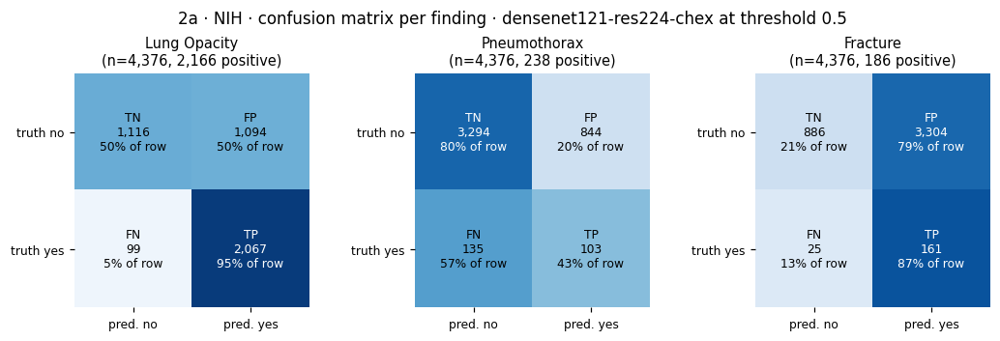

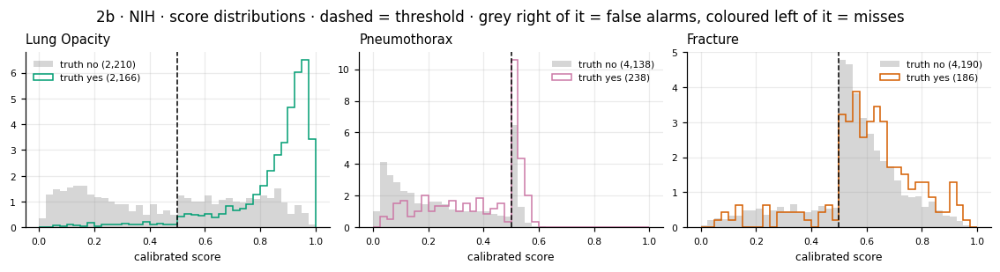

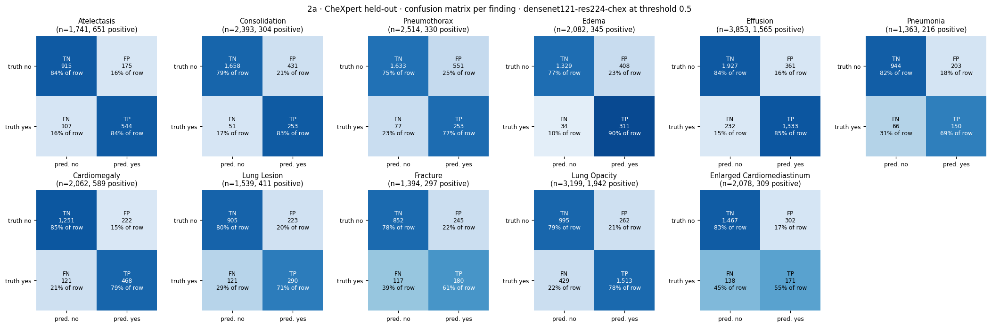

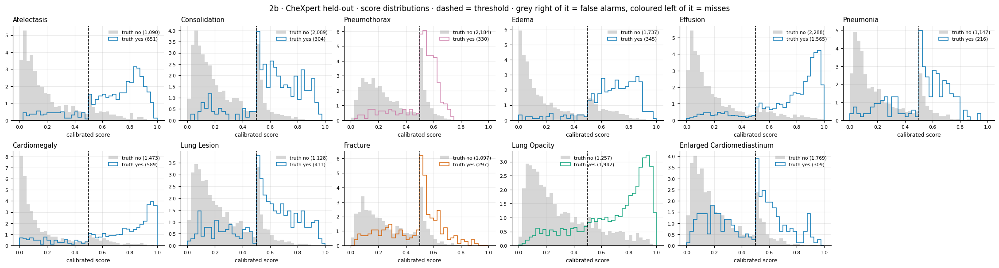

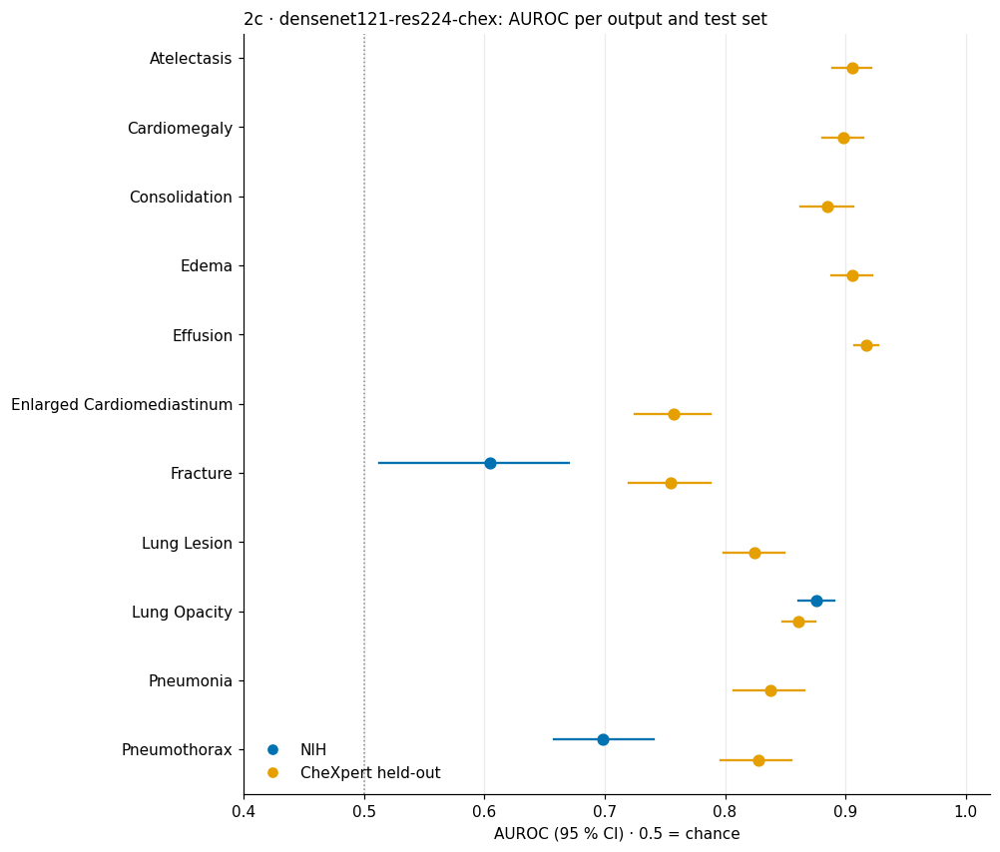

In [9]:
def plot_confusions(b, title, name, ncols=6):
    n = len(b); nc = min(n, ncols); nr = -(-n // nc)
    fig, axes = plt.subplots(nr, nc, figsize=(3.2 * nc, 3.1 * nr), layout="constrained", squeeze=False)
    for ax in axes.flat[n:]:
        ax.axis("off")
    for ax, (g, r) in zip(axes.flat, b.iterrows()):
        m = np.array([[r.TN, r.FP], [r.FN, r.TP]], int)
        share = m / np.maximum(m.sum(1, keepdims=True), 1)
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for (i, j), k in np.ndenumerate(m):
            ax.text(j, i, f"{[['TN', 'FP'], ['FN', 'TP']][i][j]}\n{k:,}\n{share[i, j]:.0%} of row", ha="center",
                    va="center", fontsize=8, color="white" if share[i, j] > 0.6 else "black")
        ax.set_xticks([0, 1], ["pred. no", "pred. yes"], fontsize=8); ax.set_yticks([0, 1], ["truth no", "truth yes"], fontsize=8)
        ax.set_title(f"{g}\n(n={int(r.n):,}, {int(r.n_pos):,} positive)", fontsize=9.5)
        ax.grid(False); ax.spines[:].set_visible(False)
    fig.suptitle(title, fontsize=11)
    save(fig, name)

def plot_scores(df, findings, truth, title, name, ncols=6):
    # where the scores of real positives and negatives fall; both scaled to the same area
    n = len(findings); nc = min(n, ncols); nr = -(-n // nc)
    fig, axes = plt.subplots(nr, nc, figsize=(3.4 * nc, 2.7 * nr), layout="constrained", squeeze=False)
    for ax in axes.flat[n:]:
        ax.axis("off")
    bins = np.linspace(0, 1, 41)
    for ax, (g, m) in zip(axes.flat, findings.items()):
        y, s = df[truth(g)].to_numpy(float), df[col(m)].to_numpy(float)
        ax.hist(s[y == 0], bins=bins, density=True, histtype="stepfilled", alpha=0.35, color=C_NEG,
                label=f"truth no ({(y == 0).sum():,})")
        if (y == 1).any():
            ax.hist(s[y == 1], bins=bins, density=True, histtype="step", lw=2, color=C_FIND.get(g, "#0072B2"),
                    label=f"truth yes ({(y == 1).sum():,})")
        ax.axvline(THRESHOLD, color="black", lw=1, ls="--")
        ax.set_title(g, loc="left", fontsize=9.5); ax.set_xlabel("calibrated score", fontsize=8)
        ax.legend(frameon=False, fontsize=7); ax.tick_params(labelsize=7)
    fig.suptitle(title, fontsize=11)
    save(fig, name)

for sn, (df, tr, fnd, _) in SETS.items():
    stem = sn.replace(" ", "_")
    plot_confusions(BASE[sn], f"2a · {sn} · confusion matrix per finding · {WEIGHTS} at threshold {THRESHOLD}",
                    f"2a_confusion_{stem}")
    plot_scores(df, fnd, tr, f"2b · {sn} · score distributions · dashed = threshold · grey right of it = false alarms, "
                "coloured left of it = misses", f"2b_scores_{stem}")

# AUROC with 95 % CI per output and test set
order = sorted(labels)
fig, ax = plt.subplots(figsize=(9, 0.55 * len(order) + 1.6), layout="constrained")
for off, (sn, b) in zip([-0.15, 0.15], BASE.items()):
    b = b.set_index("model_output")
    for k, l in enumerate(order):
        if l in b.index and not np.isnan(b.loc[l, "auroc"]):
            r = b.loc[l]
            ax.plot([r.auroc_lo, r.auroc_hi], [k + off] * 2, color=C_DATA[sn], lw=1.5)
            ax.plot(r.auroc, k + off, "o", ms=7, color=C_DATA[sn])
    ax.plot([], [], "o", color=C_DATA[sn], label=sn)
ax.axvline(0.5, color=C_NEG, lw=1, ls=":")
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.set_xlim(0.4, 1.02)
ax.set_xlabel("AUROC (95 % CI) · 0.5 = chance"); ax.legend(frameon=False, loc="lower left"); ax.grid(axis="y", visible=False)
ax.set_title(f"2c · {WEIGHTS}: AUROC per output and test set", loc="left", fontsize=11)
save(fig, "2c_auroc")

## 3 · All outputs rise together
Three views of the same question: does the model judge single findings, or one overall "looks sick" impression?
- **3a truth × output**: rows = images where a finding is truly present (plus `(no finding)`), columns = share of those
  images where each output says yes. NIH has labels for 4 findings only, so its `(no finding)` = none of these 4.
- **3b lift**: P(output j says yes | output i says yes) / P(j says yes). 1× = no link, red = the two say yes together.
- **3c overall level**: x = average of the other 10 scores, y = the score itself, one dot per image. The table below
  gives this correlation for every output.
- **3d number of yes per image** against the number of findings that are truly there.

**Finding:** every score follows the average of the others (r ≈ 0.95 for Lung Opacity, Edema, Effusion). A false
alarm rarely comes alone: on images with a false alarm, many other outputs say yes too. From here on, **overall level**
= average of the 11 scores.

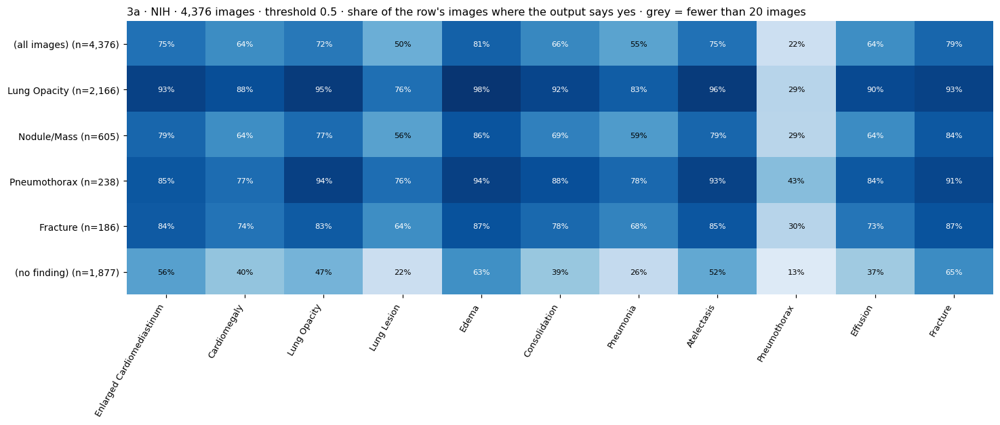

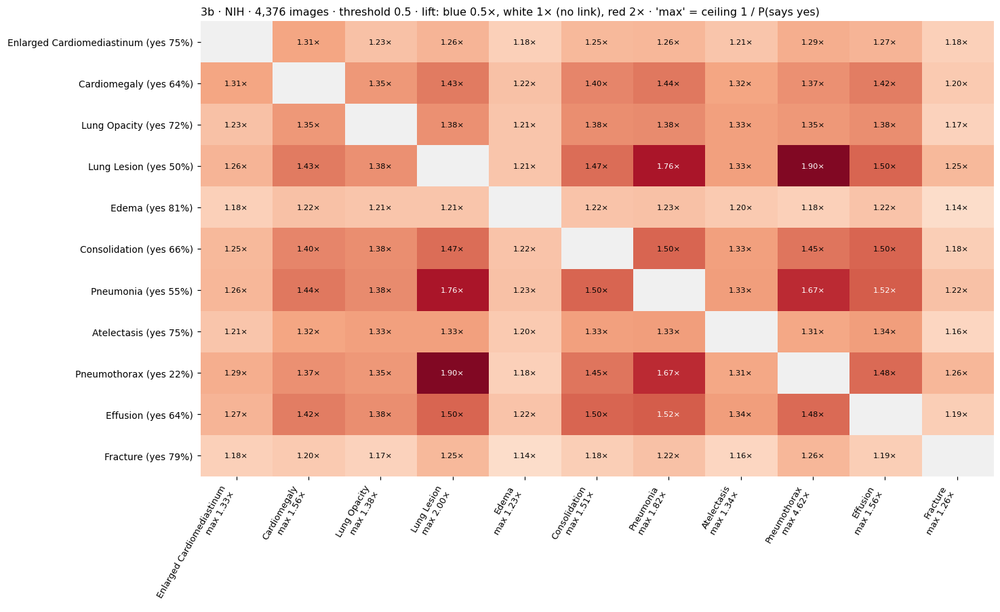

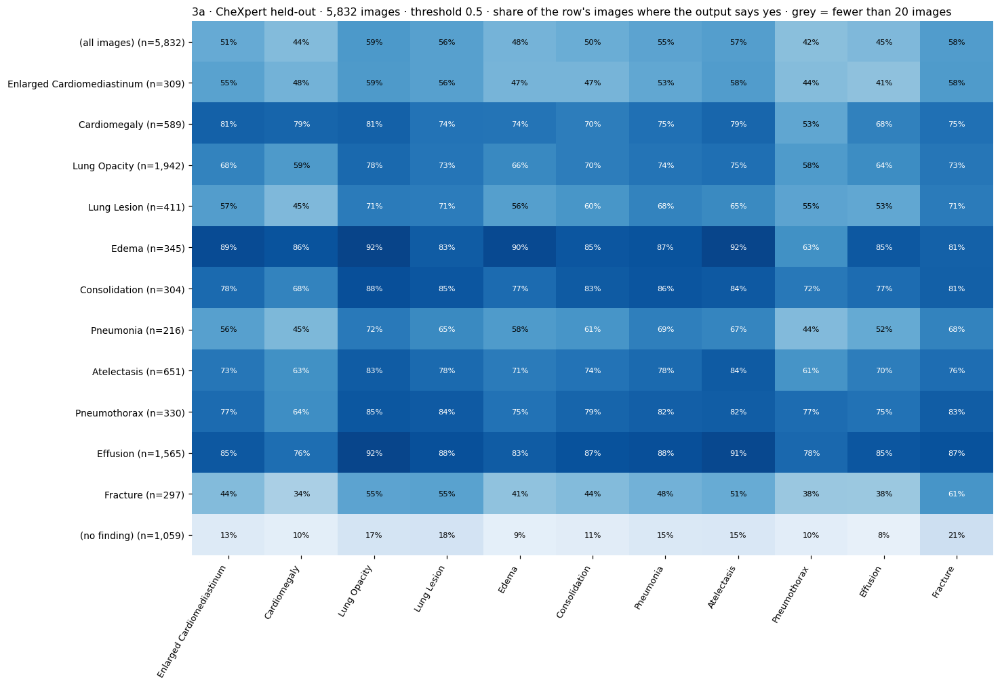

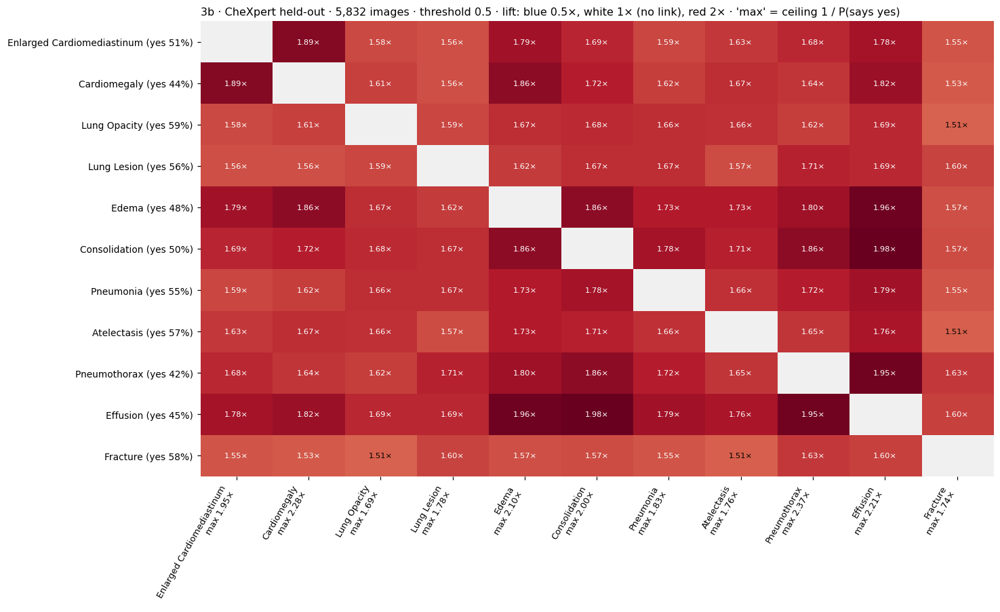

In [10]:
HIER = ["Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Nodule/Mass", "Edema",
        "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Effusion", "Fracture"]   # CheXpert label hierarchy
order_h = lambda names: sorted(names, key=lambda n: HIER.index(n) if n in HIER else len(HIER))
OUTS = order_h(labels)
fired = lambda df: pd.DataFrame({l: (df[col(l)].to_numpy(float) > THRESHOLD).astype(float) for l in OUTS})

def truth_x_output(df, truth_names, truth):
    # rows: (all images), each true finding, (no finding) = all labels 0. Cell = share of the row where the output says yes
    T = pd.DataFrame({g: df[truth(g)].to_numpy(float) for g in order_h(truth_names)})
    rows = pd.concat([pd.DataFrame({"(all images)": np.ones(len(df))}), T,
                      pd.DataFrame({"(no finding)": (T == 0).all(axis=1).astype(float)})], axis=1)
    F = fired(df).to_numpy()
    P, N = pd.DataFrame(np.nan, rows.columns, OUTS), pd.Series(0, rows.columns)
    for r in rows.columns:
        m = rows[r].to_numpy() == 1
        N[r] = int(m.sum())
        if m.sum() >= MIN_POS:
            P.loc[r] = F[m].mean(axis=0)
    return P, N

def lift(df):
    F = fired(df)
    p = F.mean()
    f, pp = F.to_numpy(), np.outer(p, p)
    with np.errstate(divide="ignore", invalid="ignore"):
        L = np.where(pp > 0, (f.T @ f / len(f)) / pp, np.nan)
    np.fill_diagonal(L, np.nan)
    return pd.DataFrame(L, OUTS, OUTS), p

def heat(M, title, name, cmap, vmin, vmax, text, ylabels, xlabels, shown=None):
    v = M.to_numpy(float); shown = v if shown is None else shown
    cm_ = plt.get_cmap(cmap).copy(); cm_.set_bad("#f0f0f0")
    fig, ax = plt.subplots(figsize=(0.8 * len(M.columns) + 4.5, 0.5 * len(M.index) + 2.6), layout="constrained")
    ax.imshow(np.ma.masked_invalid(shown), cmap=cm_, vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j), x in np.ndenumerate(v):
        if not np.isnan(x):
            ax.text(j, i, text(x), ha="center", va="center", fontsize=7.5,
                    color="white" if abs(shown[i, j]) > 0.6 * max(abs(vmin), vmax) else "black")
    ax.set_yticks(range(len(M.index)), ylabels, fontsize=9)
    ax.set_xticks(range(len(M.columns)), xlabels, rotation=60, ha="right", fontsize=8.5)
    ax.set_title(title, loc="left", fontsize=10.5); ax.grid(False); ax.spines[:].set_visible(False)
    save(fig, name)

long_rows = []
for sn, (df, tr, fnd, tnames) in SETS.items():
    stem, head = sn.replace(" ", "_"), f"{sn} · {len(df):,} images · threshold {THRESHOLD}"
    P, N = truth_x_output(df, tnames, tr)
    heat(P, f"3a · {head} · share of the row's images where the output says yes · grey = fewer than {MIN_POS} images",
         f"3a_truth_x_output_{stem}", "Blues", 0, 1, lambda x: f"{x:.0%}", [f"{r} (n={n:,})" for r, n in N.items()], OUTS)
    L, p = lift(df)
    heat(L, f"3b · {head} · lift: blue 0.5×, white 1× (no link), red 2× · 'max' = ceiling 1 / P(says yes)",
         f"3b_lift_{stem}", "RdBu_r", -1, 1, lambda x: f"{x:.2f}×", [f"{l} (yes {p[l]:.0%})" for l in OUTS],
         [f"{l}\nmax {1 / p[l]:.2f}×" if p[l] > 0 else l for l in OUTS], shown=np.log2(L.to_numpy(float)))
    long_rows += [{"test set": sn, "row": r, "output": c, "share saying yes": P.loc[r, c], "n": int(N[r])}
                  for r in P.index for c in P.columns]
pd.DataFrame(long_rows).to_csv(os.path.join(FIG_DIR, f"3a_truth_x_output_{TAG}.csv"), index=False, float_format="%.4f")

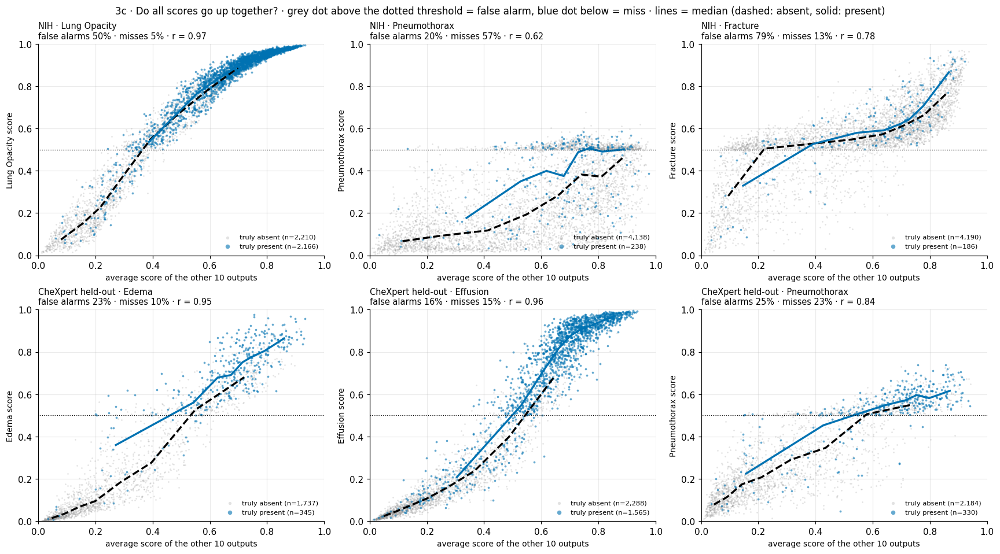

,NIH,CheXpert held-out
r with the average of the other 10,,
Enlarged Cardiomediastinum,0.86,0.91
Cardiomegaly,0.91,0.84
Lung Opacity,0.97,0.98
Lung Lesion,0.88,0.92
Edema,0.87,0.95
Consolidation,0.96,0.96
Pneumonia,0.93,0.95
Atelectasis,0.96,0.97
Pneumothorax,0.62,0.84


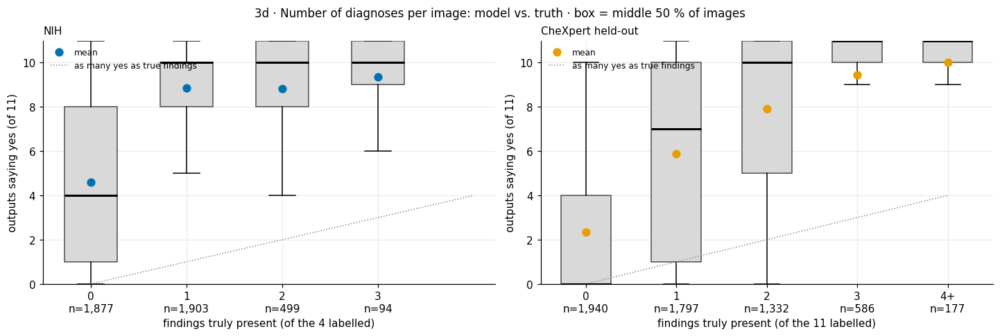

In [11]:
# ----- 3c · each score vs. the average of the other 10 ----------------------------------------------------------------
others = lambda df, o: df[[col(l) for l in labels if l != o]].mean(axis=1).to_numpy(float)
rise = pd.DataFrame({sn: {o: np.corrcoef(others(df, o), df[col(o)].to_numpy(float))[0, 1] for o in OUTS}
                     for sn, (df, *_) in SETS.items()})
rise.to_csv(os.path.join(FIG_DIR, f"3c_rise_together_r_{TAG}.csv"), float_format="%.3f")

XY = {"NIH": list(order_h(FINDINGS.values())), "CheXpert held-out": ["Edema", "Effusion", "Pneumothorax"]}
fig, axes = plt.subplots(len(XY), 3, figsize=(15.6, 4.3 * len(XY)), layout="constrained", squeeze=False)
for a, (sn, outs_) in enumerate(XY.items()):
    df, tr, fnd, _ = SETS[sn]
    for b, o in enumerate(outs_):
        ax = axes[a, b]
        g = {m: t for t, m in fnd.items()}[o]
        y, s, x = df[tr(g)].to_numpy(float), df[col(o)].to_numpy(float), others(df, o)
        for val, c, lab, sz, al in [(0, C_NEG, "truly absent", 3, 0.25), (1, "#0072B2", "truly present", 6, 0.6)]:
            m = y == val
            ax.scatter(x[m], s[m], s=sz, color=c, alpha=al, lw=0, label=f"{lab} (n={m.sum():,})")
            if m.sum() >= MIN_POS:                                   # median score in 8 bins of x
                bins = np.unique(np.percentile(x[m], np.linspace(0, 100, 9)))
                k = np.digitize(x[m], bins[1:-1])
                keep_ = [i for i in range(len(bins) - 1) if (k == i).sum() >= 10]
                ax.plot([np.median(x[m][k == i]) for i in keep_], [np.median(s[m][k == i]) for i in keep_],
                        color="black" if val == 0 else "#0072B2", lw=2.2, ls="--" if val == 0 else "-")
        ax.axhline(THRESHOLD, color="black", lw=0.8, ls=":")
        fa = ((y == 0) & (s > THRESHOLD)).sum() / max((y == 0).sum(), 1)
        mi = ((y == 1) & (s <= THRESHOLD)).sum() / max((y == 1).sum(), 1)
        ax.set_title(f"{sn} · {o}\nfalse alarms {fa:.0%} · misses {mi:.0%} · r = {rise.loc[o, sn]:.2f}", loc="left", fontsize=9.5)
        ax.set_xlabel("average score of the other 10 outputs", fontsize=9); ax.set_ylabel(f"{o} score", fontsize=9)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=7.5, loc="lower right", markerscale=2)
fig.suptitle("3c · Do all scores go up together? · grey dot above the dotted threshold = false alarm, blue dot below = miss"
             " · lines = median (dashed: absent, solid: present)", fontsize=11)
save(fig, "3c_overall_level_vs_score")
display(rise.round(2).rename_axis("r with the average of the other 10"))

# ----- 3d · how many outputs say yes vs. how many findings are truly there -----------------------------------------------
fig, axes = plt.subplots(1, len(SETS), figsize=(6.5 * len(SETS), 4.3), layout="constrained", squeeze=False)
for ax, (sn, (df, tr, fnd, tnames)) in zip(axes[0], SETS.items()):
    n_true = np.clip(np.sum([df[tr(g)].to_numpy(float) == 1 for g in tnames], axis=0), 0, 4)
    n_yes = fired(df).sum(axis=1).to_numpy()
    ks = [k for k in range(5) if (n_true == k).sum() >= MIN_POS]
    if not ks:
        continue
    ax.boxplot([n_yes[n_true == k] for k in ks], positions=ks, widths=0.55, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#d9d9d9", color="#4d4d4d"), medianprops=dict(color="black", lw=2))
    ax.plot(ks, [n_yes[n_true == k].mean() for k in ks], "o", color=C_DATA[sn], ms=7, label="mean")
    ax.plot([0, 4], [0, 4], color=C_NEG, ls=":", lw=1, label="as many yes as true findings")
    ax.set_xticks(ks, [f"{k}{'+' if k == 4 else ''}\nn={(n_true == k).sum():,}" for k in ks])
    ax.set_ylim(0, len(labels)); ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.set_xlabel(f"findings truly present (of the {len(tnames)} labelled)"); ax.set_ylabel(f"outputs saying yes (of {len(labels)})")
    ax.set_title(sn, loc="left", fontsize=10)
fig.suptitle("3d · Number of diagnoses per image: model vs. truth · box = middle 50 % of images", fontsize=11)
save(fig, "3d_number_of_yes")

## 4 · Subgroups: sex, age, view
Per output: false alarm rate (yes when truly absent) and miss rate (no when truly present), for each group.
Colour = difference to all images of that output; grey = fewer than `MIN_POS` images. CheXpert held-out has PA images
only, NIH has no device labels. Groups overlap (AP patients are older and sicker).

**Finding:** age and view change the errors most; sex only for a few outputs (men: more Fracture and Lung Lesion false alarms on CheXpert). CheXpert: the older the patient, the more false alarms
(Lung Opacity 8 % under 40 → 72 % at 75+) and the fewer misses (41 % → 9 %). The model shifts its threshold with age
instead of finding more. NIH: AP vs. PA differ (Fracture false alarms 84 % AP vs. 63 % PA).

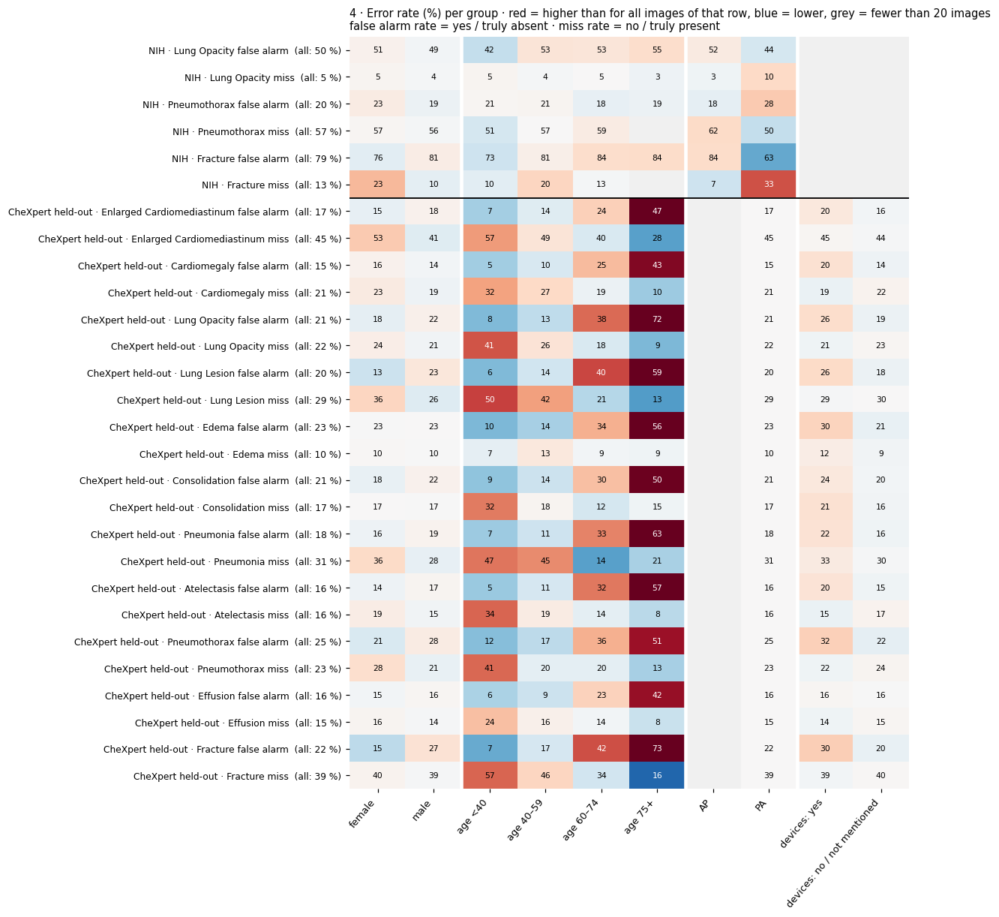

In [12]:
AGE_BINS, AGE_NAMES = [0, 40, 60, 75, 101], ["<40", "40–59", "60–74", "75+"]
GROUP_COLS = ["female", "male"] + [f"age {a}" for a in AGE_NAMES] + ["AP", "PA", "devices: yes", "devices: no / not mentioned"]

def groups(df):
    sex = df.sex.astype(str).str[0]
    age = pd.cut(df.age.where(df.age <= 100), AGE_BINS, labels=AGE_NAMES, right=False)   # NIH has a few ages > 100
    g = {"female": sex == "F", "male": sex == "M", **{f"age {a}": age == a for a in AGE_NAMES},
         "AP": df["view"] == "AP", "PA": df["view"] == "PA"}
    if "support_devices" in df:
        g["devices: yes"] = df.support_devices == 1
        g["devices: no / not mentioned"] = df.support_devices != 1
    return {k: np.asarray(v, bool) for k, v in g.items()}

rate, overall = {}, {}
for sn, (df, tr, fnd, _) in SETS.items():
    gm = groups(df)
    for o in order_h(fnd.values()):
        g = {m: t for t, m in fnd.items()}[o]
        y, yes = df[tr(g)].to_numpy(float), df[col(o)].to_numpy(float) > THRESHOLD
        for kind, base, err in [("false alarm", y == 0, (y == 0) & yes), ("miss", y == 1, (y == 1) & ~yes)]:
            name = f"{sn} · {o} {kind}"
            overall[name] = err.sum() / max(base.sum(), 1)
            rate[name] = {k: (err & m).sum() / (base & m).sum() if (base & m).sum() >= MIN_POS else np.nan
                          for k, m in gm.items()}
rate = pd.DataFrame(rate).T.reindex(columns=GROUP_COLS)
overall = pd.Series(overall)
rate.assign(all=overall).to_csv(os.path.join(FIG_DIR, f"4_error_rate_by_group_{TAG}.csv"), float_format="%.4f")

R = rate.to_numpy(float)
fig, ax = plt.subplots(figsize=(11, 0.3 * len(rate) + 2.6), layout="constrained")
text_heat(ax, R - overall.to_numpy()[:, None], np.array([[("" if np.isnan(v) else f"{100 * v:.0f}") for v in r] for r in R]),
          0.3, fontsize=7)
ax.set_yticks(range(len(rate)), [f"{n}  (all: {100 * overall[n]:.0f} %)" for n in rate.index], fontsize=8)
ax.set_xticks(range(len(GROUP_COLS)), GROUP_COLS, rotation=50, ha="right", fontsize=8.5)
for x in (1.5, 5.5, 7.5):
    ax.axvline(x, color="white", lw=3)
for i in range(1, len(rate)):                                      # black line between the test sets
    if rate.index[i].split(" · ")[0] != rate.index[i - 1].split(" · ")[0]:
        ax.axhline(i - 0.5, color="black", lw=1.2)
ax.set_title(f"4 · Error rate (%) per group · red = higher than for all images of that row, blue = lower, grey = fewer than "
             f"{MIN_POS} images\nfalse alarm rate = yes / truly absent · miss rate = no / truly present", loc="left", fontsize=9.5)
save(fig, "4_error_rate_by_group")

## 5 · Age on healthy images
Is the age effect only because older patients are sicker? Here only images where **nothing** is present:
NIH = all 4 Google labels 0 and the NIH report says "No Finding"; CheXpert = all 11 labels 0. Every "yes" is a false
alarm, and every value is computed within its age group (so a group with more people does not get higher values).
- **5a** left: age vs. overall level, one dot per healthy image, with the rise per 10 years (95 % CI, resampling
  patients). Right: how many outputs say yes, healthy vs. all images.
- **5b** false alarm rate per output and age group.

**Finding:** yes, also on healthy images the level rises with age: CheXpert +0.049 per 10 years [0.043–0.055], NIH
+0.013 [0.005–0.022] (NIH has few old patients, and AP vs. PA matters more there). Every output is affected, not
a single one. The model reads age as sickness.

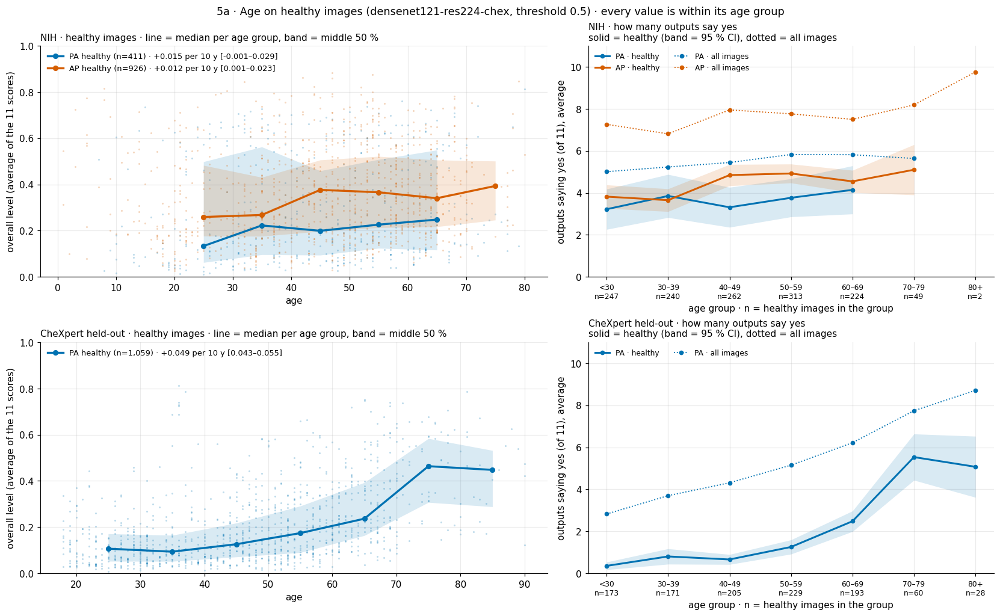

,test set,view,healthy images,patients,level rise per 10 years,lo,hi
0,NIH,all,1337,803,0.0134,0.0051,0.0216
1,NIH,AP,926,468,0.0120,0.0013,0.0228
2,NIH,PA,411,370,0.0148,-0.0008,0.0294
3,CheXpert held-out,all,1059,955,0.0491,0.0430,0.0549
4,CheXpert held-out,PA,1059,955,0.0491,0.0430,0.0549


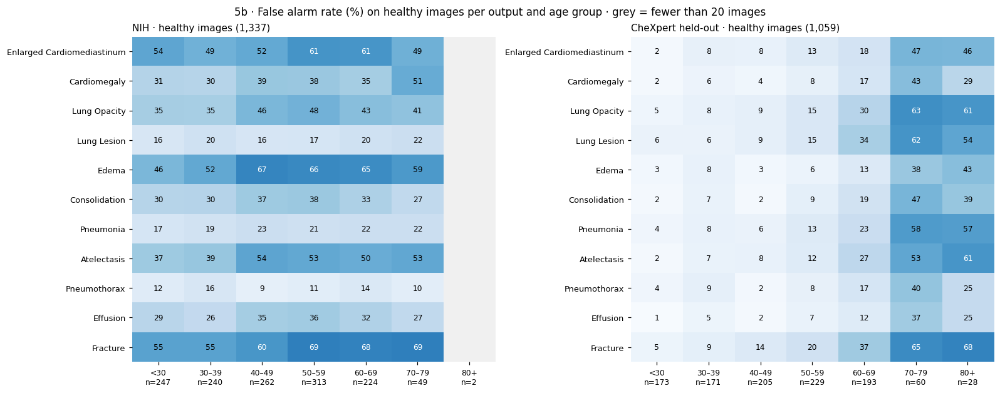

In [13]:
AGE10_BINS, AGE10 = [0, 30, 40, 50, 60, 70, 80, 101], ["<30", "30–39", "40–49", "50–59", "60–69", "70–79", "80+"]
AGE_MID = dict(zip(AGE10, [25, 35, 45, 55, 65, 75, 85]))           # where each age group is drawn

def healthy(set_name, df):
    if set_name == "NIH":
        g = np.all([df[gcol(x)].to_numpy() == 0 for x in GT_LABELS], axis=0)
        return g & (df.nih_finding_labels == "No Finding").to_numpy()
    return np.all([df[xcol(x)].to_numpy(float) == 0 for x in CHEX_FINDINGS], axis=0)

def prep(df, m):
    age = df.age.to_numpy(float)
    d = df[m & (age > 0) & (age <= 100)].reset_index(drop=True)
    F = fired(d)
    return d.assign(level=d[[col(l) for l in labels]].mean(axis=1).to_numpy(), n_yes=F.sum(axis=1).to_numpy(),
                    age10=pd.cut(d.age, AGE10_BINS, labels=AGE10, right=False)), F

def slope_ci(d, n_boot=500):
    # rise of the overall level per 10 years (straight-line fit), 95 % CI from resampling patients
    x, v = d.age.to_numpy(float) / 10, d.level.to_numpy(float)
    if len(d) < MIN_POS:
        return np.nan, np.nan, np.nan
    b = np.polyfit(x, v, 1)[0]
    idx_by_pat = d.groupby("patient_id").indices
    pats, rng, bs = np.array(list(idx_by_pat)), np.random.default_rng(SEED), []
    for _ in range(n_boot):
        i = np.concatenate([idx_by_pat[p] for p in rng.choice(pats, len(pats))])
        bs.append(np.polyfit(x[i], v[i], 1)[0])
    return b, *np.percentile(bs, [2.5, 97.5])

H, H_all, slopes = {}, {}, []
for sn, (df, *_) in SETS.items():
    H[sn] = prep(df, healthy(sn, df))
    H_all[sn] = prep(df, np.ones(len(df), bool))
    d = H[sn][0]
    for v in [None] + sorted(d["view"].unique()):
        dv = d if v is None else d[d["view"] == v].reset_index(drop=True)
        b, lo, hi = slope_ci(dv)
        slopes.append({"test set": sn, "view": v or "all", "healthy images": len(dv), "patients": dv.patient_id.nunique(),
                       "level rise per 10 years": b, "lo": lo, "hi": hi})
slopes = pd.DataFrame(slopes)
slopes.to_csv(os.path.join(FIG_DIR, f"5_age_slope_healthy_{TAG}.csv"), index=False, float_format="%.4f")

# ----- 5a · overall level and number of yes vs. age, healthy images ----------------------------------------------
fig, axes = plt.subplots(len(H), 2, figsize=(15, 4.6 * len(H)), layout="constrained", squeeze=False,
                         gridspec_kw={"width_ratios": [1.25, 1]})
for a, (sn, (d, F)) in enumerate(H.items()):
    views = [v for v in ("PA", "AP") if (d["view"] == v).sum() >= MIN_POS]
    ax = axes[a, 0]
    for v in views:
        dv = d[d["view"] == v]
        ax.scatter(dv.age, dv.level, s=4, alpha=0.25, lw=0, color=C_VIEW[v])
        g = dv.groupby("age10", observed=True)["level"]
        q = pd.DataFrame({"n": g.size(), "med": g.median(), "lo": g.quantile(0.25), "hi": g.quantile(0.75)})
        q = q[q.n >= MIN_POS]
        mid = [AGE_MID[g_] for g_ in q.index]
        ax.fill_between(mid, q.lo, q.hi, color=C_VIEW[v], alpha=0.15, lw=0)
        r = slopes[(slopes["test set"] == sn) & (slopes["view"] == v)].iloc[0]
        ax.plot(mid, q.med, "o-", color=C_VIEW[v], lw=2.2, ms=5,
                label=f"{v} healthy (n={len(dv):,}) · +{r['level rise per 10 years']:.3f} per 10 y "
                      f"[{r.lo:.3f}–{r.hi:.3f}]")
    ax.set_xlabel("age"); ax.set_ylabel("overall level (average of the 11 scores)"); ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax.set_title(f"{sn} · healthy images · line = median per age group, band = middle 50 %", loc="left", fontsize=10)

    ax = axes[a, 1]
    x = np.arange(len(AGE10))
    for kind, (dd, _), ls in [("healthy", H[sn], "-"), ("all images", H_all[sn], ":")]:
        for v in views:
            dv = dd[dd["view"] == v]
            g = dv.groupby("age10", observed=True)["n_yes"]
            q = pd.DataFrame({"n": g.size(), "mean": g.mean(), "se": g.std() / np.sqrt(g.size())}).reindex(AGE10)
            q = q.where(q.n >= MIN_POS)
            if kind == "healthy":
                ax.fill_between(x, q["mean"] - 1.96 * q.se, q["mean"] + 1.96 * q.se, color=C_VIEW[v], alpha=0.15, lw=0)
            ax.plot(x, q["mean"], "o" + ls, color=C_VIEW[v], lw=2 if kind == "healthy" else 1.2, ms=4,
                    label=f"{v} · {kind}")
    n_h = d.groupby("age10", observed=True).size().reindex(AGE10, fill_value=0)
    ax.set_xticks(x, [f"{g}\nn={n:,}" for g, n in zip(AGE10, n_h)], fontsize=8)
    ax.set_ylim(0, len(labels)); ax.set_ylabel(f"outputs saying yes (of {len(labels)}), average")
    ax.set_xlabel("age group · n = healthy images in the group")
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncols=2)
    ax.set_title(f"{sn} · how many outputs say yes\nsolid = healthy (band = 95 % CI), dotted = all images",
                 loc="left", fontsize=10)
fig.suptitle(f"5a · Age on healthy images ({WEIGHTS}, threshold {THRESHOLD}) · every value is within its age group",
             fontsize=11.5)
save(fig, "5a_age_healthy")
display(slopes.round(4))

# ----- 5b · false alarm rate per output and age group, healthy images --------------------------------------------
fig, axes = plt.subplots(1, len(H), figsize=(6.2 * len(H) + 2, 5.6), layout="constrained", squeeze=False)
for ax, (sn, (d, F)) in zip(axes[0], H.items()):
    n = d.groupby("age10", observed=True).size().reindex(AGE10, fill_value=0)
    P = F.groupby(d.age10.to_numpy(), observed=True).mean().reindex(AGE10).T          # outputs x age groups
    P = P.where(np.broadcast_to(n.to_numpy()[None, :] >= MIN_POS, P.shape))
    v = P.to_numpy(float)
    cm_ = plt.get_cmap("Blues").copy(); cm_.set_bad("#f0f0f0")
    ax.imshow(np.ma.masked_invalid(v), cmap=cm_, vmin=0, vmax=1, aspect="auto")
    for (i, j), x in np.ndenumerate(v):
        if not np.isnan(x):
            ax.text(j, i, f"{100 * x:.0f}", ha="center", va="center", fontsize=8, color="white" if x > 0.6 else "black")
    ax.set_yticks(range(len(P.index)), P.index, fontsize=8.5)
    ax.set_xticks(range(len(AGE10)), [f"{g}\nn={k:,}" for g, k in zip(AGE10, n)], fontsize=8)
    ax.grid(False); ax.spines[:].set_visible(False)
    ax.set_title(f"{sn} · healthy images ({len(d):,})", loc="left", fontsize=10)
fig.suptitle(f"5b · False alarm rate (%) on healthy images per output and age group · grey = fewer than {MIN_POS} images",
             fontsize=11)
save(fig, "5b_false_alarms_healthy_by_age")

## 6 · Image properties: what in the picture goes with the overall level?
For every image, simple properties computed like the model's crop (centre square, 256 px):

| Property | Meaning |
|---|---|
| brightness | average grey value (0 = black, 1 = white) |
| contrast | spread of the grey values (standard deviation) |
| dark share | share of nearly black pixels (< 0.1) |
| bright share | share of nearly white pixels (> 0.9) |
| sharpness | strength of fine edges (variance of the Laplacian) |
| lung-area brightness | average grey value in two boxes where the lungs usually are |

- **6a** XY: property vs. overall level on healthy images, per view. Line = median level in 8 bins of the property.
- **6b** summary: rank correlation with the level, with the level after removing age, and with age.

**Finding:** no clear cutoff. On CheXpert every property goes with the level only weakly (|r| ≤ 0.15), so the age
effect of section 5 is more likely anatomy than image quality. On NIH PA the correlations are larger, but they come
mostly from one scanner (pixel spacing 0.194 mm): the flattest images (lowest contrast, no bright pixels), and its
healthy images get ≈ 10 of 11 yes, other scanners 0.8–1.5. Section 7 tests whether contrast is the cause.

NIH: properties of 4,375 images in 41s (1,337 healthy)
CheXpert held-out: properties of 5,832 images in 13s (1,059 healthy)


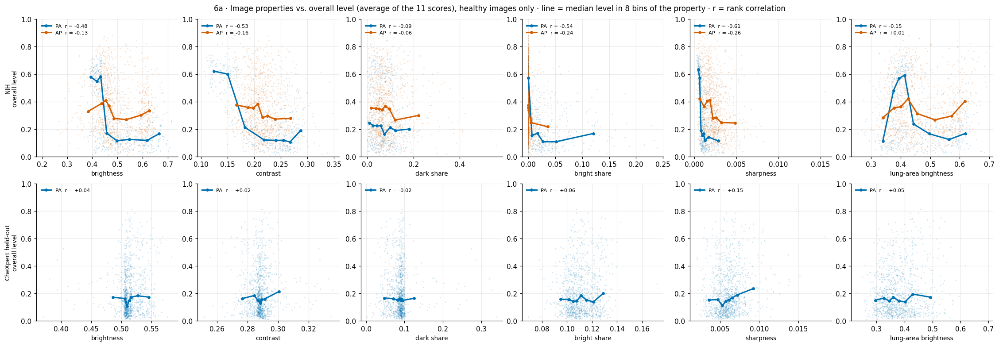

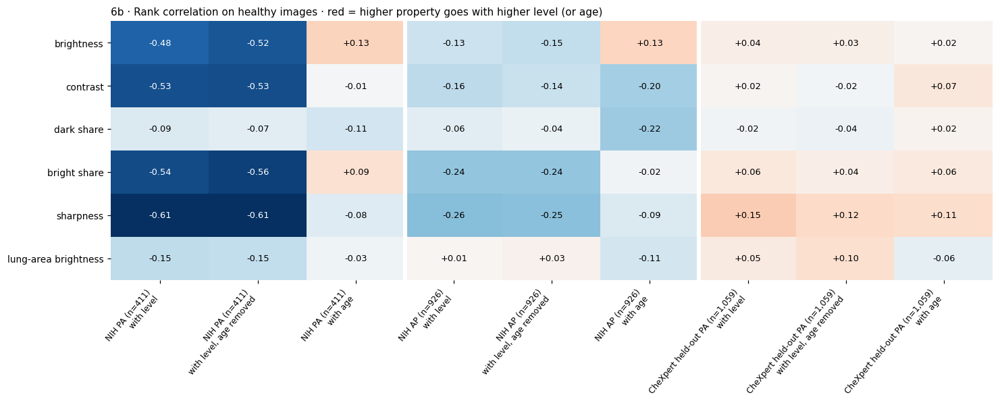

,images,contrast,bright_share,outputs_saying_yes
NIH PA healthy · pixel spacing (mm),,,,
0.139,39,0.218,0.000,0.769
0.143,153,0.265,0.020,1.294
0.168,72,0.236,0.071,1.528
0.171,38,0.201,0.003,1.447
0.194,109,0.142,0.000,10.064


In [14]:
from concurrent.futures import ThreadPoolExecutor

PROPS = ["brightness", "contrast", "dark share", "bright share", "sharpness", "lung-area brightness"]

def image_props(path):
    im = Image.open(path).convert("L")
    w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((256, 256), Image.BILINEAR)
    a = np.asarray(im, np.float32) / 255
    lap = a[1:-1, :-2] + a[1:-1, 2:] + a[:-2, 1:-1] + a[2:, 1:-1] - 4 * a[1:-1, 1:-1]
    lungs = np.r_[a[64:180, 38:115].ravel(), a[64:180, 141:218].ravel()]
    return {"brightness": a.mean(), "contrast": a.std(), "dark share": (a < 0.1).mean(), "bright share": (a > 0.9).mean(),
            "sharpness": lap.var(), "lung-area brightness": lungs.mean()}

def paths_of(set_name, df):
    if set_name == "NIH":
        return [nih_path[f] for f in df.image_id]
    return [os.path.join(CHEX_DIR, p.replace("CheXpert-v1.0-small/", "")) for p in df.path]

PR = {}
for sn, (df, *_) in SETS.items():
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        p = pd.DataFrame(list(ex.map(image_props, paths_of(sn, df))))
    p["level"] = df[[col(l) for l in labels]].mean(axis=1).to_numpy()
    p["n_yes"] = fired(df).sum(axis=1).to_numpy()
    p["age"], p["view"], p["patient_id"] = df.age.to_numpy(float), df["view"].to_numpy(), df.patient_id.to_numpy()
    p["healthy"] = healthy(sn, df)
    p["id"] = df.image_id.to_numpy() if sn == "NIH" else df.path.to_numpy()
    if sn == "NIH":
        p["pixel_spacing"] = df.pixel_spacing_x.round(3).to_numpy()
    p = p[(p.age > 0) & (p.age <= 100)]
    PR[sn] = p
    p.to_csv(os.path.join(FIG_DIR, f"6_image_properties_{sn.replace(' ', '_')}_{TAG}.csv"), index=False, float_format="%.5f")
    print(f"{sn}: properties of {len(p):,} images in {time.time() - t0:.0f}s ({int(p.healthy.sum()):,} healthy)")

rank = lambda v: pd.Series(np.asarray(v, float)).rank().to_numpy()

def spearman(x, y):
    return np.corrcoef(rank(x), rank(y))[0, 1]

def partial(x, y, z):
    # rank correlation of x and y after removing a straight-line effect of z from both
    rx, ry, rz = rank(x), rank(y), rank(z)
    res = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    return np.corrcoef(res(rx), res(ry))[0, 1]

GROUPS6 = [(sn, v) for sn, p in PR.items() for v in ("PA", "AP") if (p.healthy & (p["view"] == v)).sum() >= MIN_POS]

# ----- 6a · XY: property vs. overall level, healthy images ----------------------------------------------------------
fig, axes = plt.subplots(len(PR), len(PROPS), figsize=(3.4 * len(PROPS), 3.5 * len(PR)), layout="constrained", squeeze=False)
for a, (sn, p) in enumerate(PR.items()):
    for b, prop in enumerate(PROPS):
        ax = axes[a, b]
        for v in ("PA", "AP"):
            if (sn, v) not in GROUPS6:
                continue
            q = p[p.healthy & (p["view"] == v)]
            ax.scatter(q[prop], q.level, s=3, alpha=0.2, lw=0, color=C_VIEW[v])
            bins = np.unique(np.percentile(q[prop], np.linspace(0, 100, 9)))
            k = np.digitize(q[prop], bins[1:-1])
            keep_ = [i for i in range(len(bins) - 1) if (k == i).sum() >= 10]
            ax.plot([q[prop].to_numpy()[k == i].mean() for i in keep_], [np.median(q.level.to_numpy()[k == i]) for i in keep_],
                    "o-", color=C_VIEW[v], lw=2, ms=3.5, label=f"{v}  r = {spearman(q[prop], q.level):+.2f}")
        ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=7.5, loc="upper left")
        ax.set_xlabel(prop, fontsize=9)
        if b == 0:
            ax.set_ylabel(f"{sn}\noverall level", fontsize=9)
fig.suptitle("6a · Image properties vs. overall level (average of the 11 scores), healthy images only · "
             "line = median level in 8 bins of the property · r = rank correlation", fontsize=11)
save(fig, "6a_properties_vs_level")

# ----- 6b · summary: correlation with the level, also after removing age, and with age ---------------------------------
summ = {}
for sn, v in GROUPS6:
    q = PR[sn][PR[sn].healthy & (PR[sn]["view"] == v)]
    for prop in PROPS:
        summ.setdefault(prop, {})
        summ[prop][(f"{sn} {v} (n={len(q):,})", "with level")] = spearman(q[prop], q.level)
        summ[prop][(f"{sn} {v} (n={len(q):,})", "with level, age removed")] = partial(q[prop], q.level, q.age)
        summ[prop][(f"{sn} {v} (n={len(q):,})", "with age")] = spearman(q[prop], q.age)
summ = pd.DataFrame(summ).T
summ.to_csv(os.path.join(FIG_DIR, f"6b_properties_summary_{TAG}.csv"), float_format="%.3f")
v = summ.to_numpy(float)
fig, ax = plt.subplots(figsize=(1.15 * v.shape[1] + 3, 0.5 * len(PROPS) + 2.4), layout="constrained")
text_heat(ax, v, np.array([[f"{x:+.2f}" for x in r] for r in v]), 0.6, fontsize=8.5)
ax.set_yticks(range(len(PROPS)), PROPS, fontsize=9)
ax.set_xticks(range(v.shape[1]), [f"{g}\n{c}" for g, c in summ.columns], rotation=50, ha="right", fontsize=8)
for x in range(3, v.shape[1], 3):
    ax.axvline(x - 0.5, color="white", lw=4)
ax.set_title("6b · Rank correlation on healthy images · red = higher property goes with higher level (or age)",
             loc="left", fontsize=10)
save(fig, "6b_properties_summary")

# NIH PA healthy images per scanner (pixel spacing): contrast and how many outputs say yes
q = PR["NIH"][PR["NIH"].healthy & (PR["NIH"]["view"] == "PA")]
display(q.groupby("pixel_spacing").agg(images=("level", "size"), contrast=("contrast", "median"),
                                       bright_share=("bright share", "median"), outputs_saying_yes=("n_yes", "mean"))
         .query("images >= 10").round(3).rename_axis("NIH PA healthy · pixel spacing (mm)"))

## 7 · Contrast perturbation: does low contrast cause the "everything is sick" answers?
Healthy NIH PA images only, so every "yes" is a false alarm. Contrast `s`: grey = mean + s · (grey − mean),
applied to the image file before the model's own preprocessing (s = 1 = unchanged, checked against the stored scores).
- **0.194 scanner** (flat images): make them harder (s > 1). Do the false alarms disappear?
- **other scanners** (random sample): make them flatter (s < 1). Do false alarms appear?

Left: overall level, one thin line per image, bold = median. Right: outputs saying yes per image (95 % CI).

**Finding:** both directions work. 0.194 scanner: 10.1 → 1.8 false alarms per image at ×2 contrast (98 % of
images get fewer). Other scanners: 1.3 → 9.9 at ×0.4. Low contrast causes the "everything is sick" answers.
Pneumothorax resists flattening longest.

healthy NIH PA images: 109 from the 0.194 scanner, 150 from other scanners
contrast     32 / 2072  2s
contrast    672 / 2072  19s
contrast   1312 / 2072  36s
contrast   1952 / 2072  52s
contrast done: 2,072 images in 55s
check: unchanged image vs. stored scores, max difference of the level = 2.7e-07


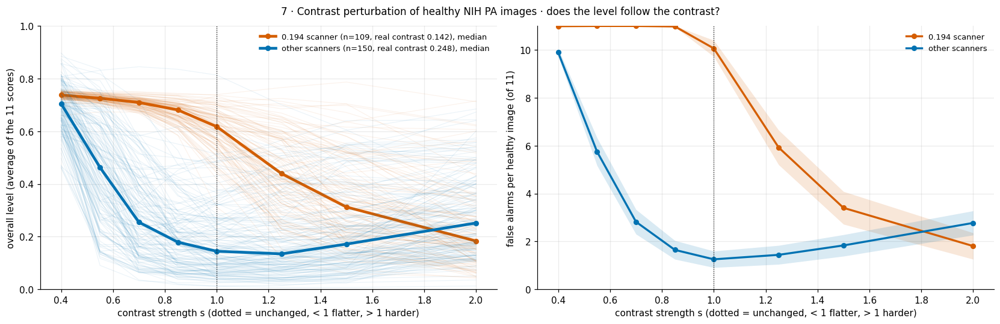

In [15]:
SCANNER, N_OTHER = 0.194, 150
STRENGTHS = [0.4, 0.55, 0.7, 0.85, 1.0, 1.25, 1.5, 2.0]
C_GRP = {f"{SCANNER} scanner": "#D55E00", "other scanners": "#0072B2"}

def contrast(a, s):
    m = a.mean()
    return np.clip(m + s * (a - m), 0, 1)

class ContrastNIH(torch.utils.data.Dataset):
    # same preprocessing as the NIH loader: grey 0…255 -> −1024…1024, centre crop, 224 px
    def __init__(self, jobs):
        self.jobs = jobs                                       # list of (image_id, strength)
    def __len__(self):
        return len(self.jobs)
    def __getitem__(self, i):
        f, s = self.jobs[i]
        a = contrast(np.asarray(Image.open(nih_path[f]).convert("L"), np.float32) / 255, s)
        return {"img": torch.from_numpy(transform(((2 * a - 1) * 1024)[None]).astype(np.float32))}

sp = out.pixel_spacing_x.round(3).to_numpy()
base = healthy("NIH", out) & (out["view"] == "PA").to_numpy() & ((out.age > 0) & (out.age <= 100)).to_numpy()
idx_a = np.flatnonzero(base & (sp == SCANNER))
idx_b = np.flatnonzero(base & (sp != SCANNER))
idx_b = np.random.default_rng(SEED).choice(idx_b, min(N_OTHER, len(idx_b)), replace=False)
pick = pd.DataFrame({"image_id": out.image_id.to_numpy()[np.r_[idx_a, idx_b]],
                     "group": [f"{SCANNER} scanner"] * len(idx_a) + ["other scanners"] * len(idx_b)})
print(f"healthy NIH PA images: {len(idx_a)} from the {SCANNER} scanner, {len(idx_b)} from other scanners")

jobs = [(f, s) for s in STRENGTHS for f in pick.image_id]
res = run_model(ContrastNIH(jobs), "contrast", every=20)
res.insert(0, "strength", [j[1] for j in jobs]); res.insert(0, "image_id", [j[0] for j in jobs])
res = res.merge(pick, on="image_id")
res["level"] = res[[col(l) for l in labels]].mean(axis=1)
res["n_yes"] = (res[[col(l) for l in labels]] > THRESHOLD).sum(axis=1)
res.to_csv(os.path.join(FIG_DIR, f"7_contrast_perturbation_{TAG}.csv"), index=False, float_format="%.5f")

# check: s = 1 (unchanged image) must give the stored scores
r1 = res[res.strength == 1.0].set_index("image_id").level
d = (r1 - out.set_index("image_id").loc[r1.index, [col(l) for l in labels]].mean(axis=1)).abs().max()
print(f"check: unchanged image vs. stored scores, max difference of the level = {d:.1e}")
assert len(r1) == 0 or d < 1e-3, "preprocessing differs from the baseline run"

real_c = PR["NIH"].set_index("id").reindex(pick.image_id)["contrast"].groupby(pick.group.to_numpy()).median()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for g, c in C_GRP.items():
    r = res[res.group == g]
    if r.empty:
        continue
    w = r.pivot(index="image_id", columns="strength", values="level")[STRENGTHS]
    for _, line in w.iterrows():
        axes[0].plot(STRENGTHS, line.to_numpy(), color=c, alpha=0.08, lw=0.8)
    axes[0].plot(STRENGTHS, w.median().to_numpy(), "o-", color=c, lw=3, ms=5,
                 label=f"{g} (n={len(w)}, real contrast {real_c.get(g, np.nan):.3f}), median")
    q = r.groupby("strength").n_yes.agg(["mean", "std", "size"]).reindex(STRENGTHS)
    se = q["std"] / np.sqrt(q["size"])
    axes[1].fill_between(STRENGTHS, q["mean"] - 1.96 * se, q["mean"] + 1.96 * se, color=c, alpha=0.15, lw=0)
    axes[1].plot(STRENGTHS, q["mean"], "o-", color=c, lw=2.2, ms=5, label=g)
for ax, yl, top in [(axes[0], "overall level (average of the 11 scores)", 1), (axes[1], f"false alarms per healthy image (of {len(labels)})", len(labels))]:
    ax.axvline(1.0, color="black", lw=0.8, ls=":"); ax.set_ylim(0, top); ax.set_ylabel(yl)
    ax.set_xlabel("contrast strength s (dotted = unchanged, < 1 flatter, > 1 harder)"); ax.legend(frameon=False, fontsize=8.5)
fig.suptitle("7 · Contrast perturbation of healthy NIH PA images · does the level follow the contrast?", fontsize=11)
save(fig, "7_contrast_perturbation")

## 8 · Augmentations: which output is robust against what?
Every labelled image of both test sets, brought to a 512 px centre square, changed, then preprocessed exactly like the
model expects. "Baseline" = the same pipeline without a change, so every difference comes from the augmentation.
Four strengths each (pixels refer to the 512 px image):

| Augmentation | What it does | Strengths |
|---|---|---|
| contrast down / up | grey = mean + s · (grey − mean) | ×0.85 … ×0.4 / ×1.25 … ×2.0 |
| blur | Gaussian blur with σ pixels | σ 1, 2, 4, 8 |
| sharpen | unsharp mask: grey + a · (grey − blurred) | 0.5, 1, 2, 4 |
| warp whole image | smooth random distortion, at most d pixels | 8, 16, 32, 48 px (48 ≈ 9 % of the width) |
| warp lungs only | the same inside two fixed lung boxes | 8, 16, 32, 48 px |

- **8a** example images: baseline and every strength (warp rows with a grid drawn on top, for display only).
- **8b** one figure per augmentation and test set: a 2×2 confusion matrix per output and strength (same layout as the
  other pair). Red frame = false alarm rate or miss rate differs from the baseline by ≥ 10 points.
- **8c** summary: average false alarm rate, miss rate and outputs saying yes vs. strength, one line per augmentation.
- **8d** per output: change at the strongest level of each augmentation.

**Finding (last full run):**
- **Less contrast** is the strongest lever. NIH false alarms 49 % → 89 % on average. On CheXpert (more contrast to begin
  with) nothing much happens until ×0.4, then 17 % → 41 %. Together with section 6, the jump seems to start when the
  contrast gets as low as on the 0.194 scanner, but it is gradual, not a clear cutoff.
- **Opacity-based group** (Edema, Atelectasis, Lung Opacity, Cardiomegaly, Enlarged Cardiomediastinum): less contrast
  and blur raise their false alarms (+30 to +69 points at the strongest level).
- **Local-variation group**: Pneumothorax reacts the other way. Flattening or blurring makes it miss
  (CheXpert misses +64 points at ×0.4), sharpening makes it raise false alarms (+45 at 2). Consolidation and Effusion
  also fire much more when sharpened (+76, +45).
- **Warp** raises all outputs evenly (+10 to +25 points of false alarms at 48 px, fewer misses): the overall level rises.
  Warping only the lungs gives the same result (but the lung boxes cover most of the chest).
- The strongest levels are not realistic images. At realistic strengths (steps 1–2) only less contrast on NIH changes much.

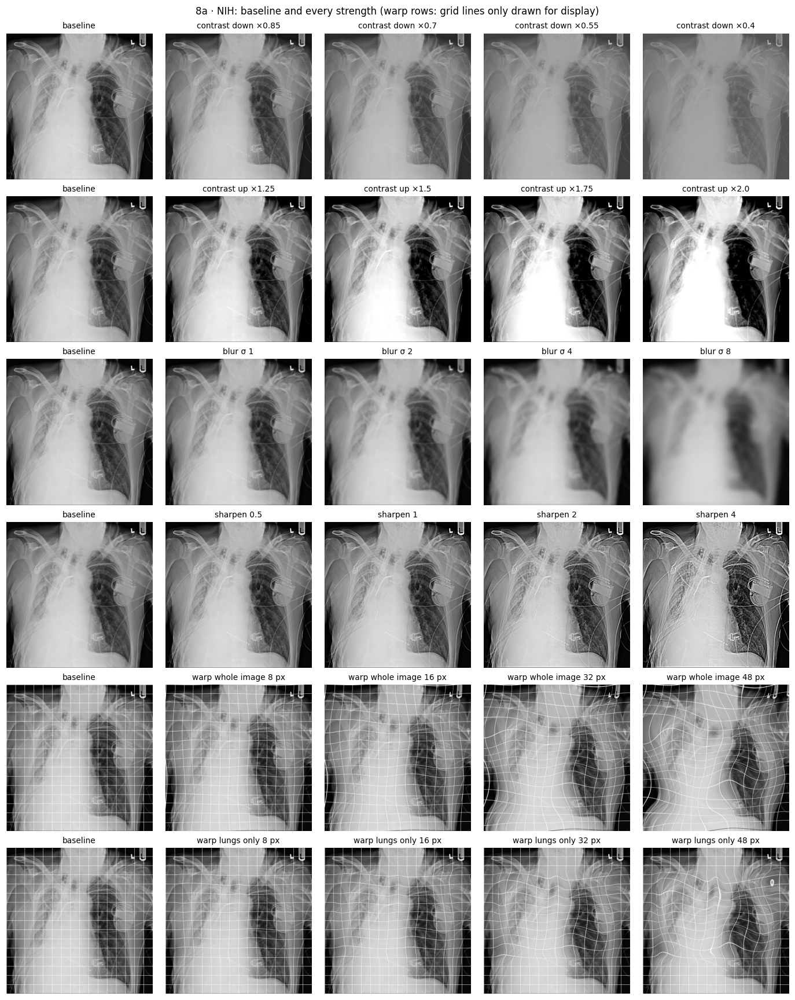

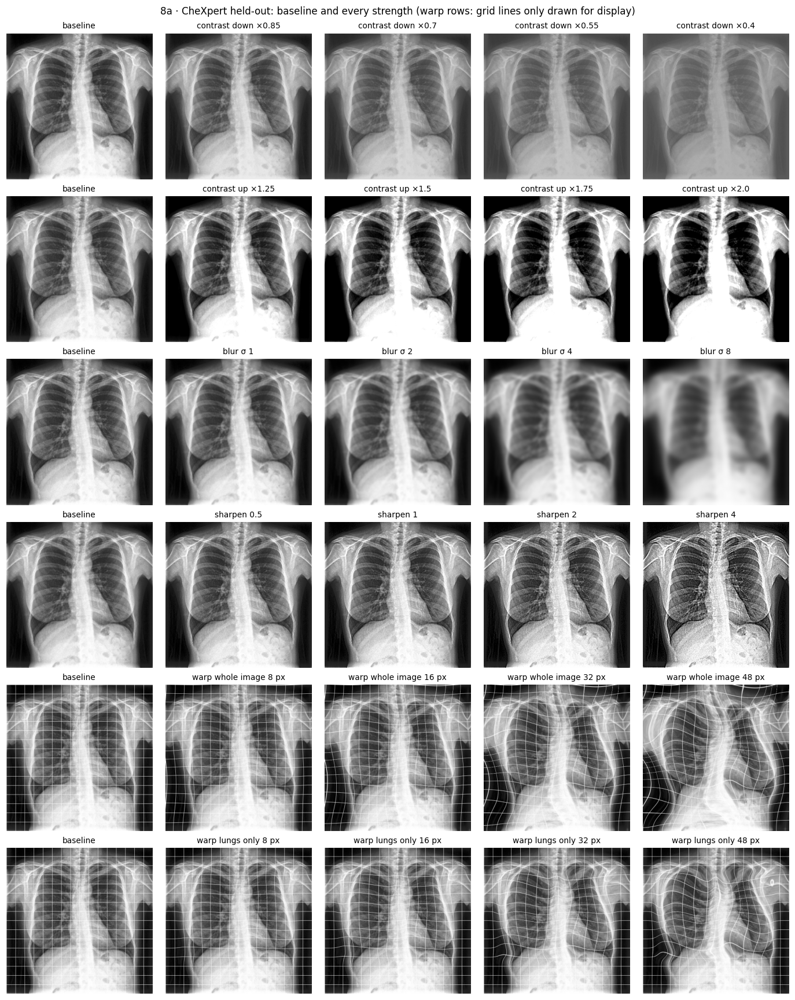

NIH      64 / 109,400  1s
NIH   6,464 / 109,400  28s
NIH  12,864 / 109,400  56s
NIH  19,264 / 109,400  83s
NIH  25,664 / 109,400  111s
NIH  32,064 / 109,400  139s
NIH  38,464 / 109,400  166s
NIH  44,864 / 109,400  203s
NIH  51,264 / 109,400  249s
NIH  57,664 / 109,400  313s
NIH  64,064 / 109,400  356s
NIH  70,464 / 109,400  399s
NIH  76,864 / 109,400  456s
NIH  83,264 / 109,400  534s
NIH  89,664 / 109,400  612s
NIH  96,064 / 109,400  688s
NIH 102,464 / 109,400  763s
NIH 108,864 / 109,400  838s
NIH: 4,376 images × 25 versions in 877s
CheXpert held-out      64 / 142,475  1s
CheXpert held-out   6,464 / 142,475  29s
CheXpert held-out  12,864 / 142,475  57s
CheXpert held-out  19,264 / 142,475  85s
CheXpert held-out  25,664 / 142,475  112s
CheXpert held-out  32,064 / 142,475  140s
CheXpert held-out  38,464 / 142,475  168s
CheXpert held-out  44,864 / 142,475  196s
CheXpert held-out  51,264 / 142,475  223s
CheXpert held-out  57,664 / 142,475  260s
CheXpert held-out  64,064 / 142,475  302s
CheX

In [16]:
from scipy import ndimage

N_IMAGES, SIDE, FRAME_PP = None, 512, 10        # N_IMAGES = None: all labelled images (≈ 35 min on a T4). 2000 = quicker
AUGS = {"contrast down": ("contrast", [0.85, 0.7, 0.55, 0.4], "×{}"),
        "contrast up": ("contrast", [1.25, 1.5, 1.75, 2.0], "×{}"),
        "blur": ("blur", [1, 2, 4, 8], "σ {}"),
        "sharpen": ("sharpen", [0.5, 1, 2, 4], "{}"),
        "warp whole image": ("warp", [8, 16, 32, 48], "{} px"),
        "warp lungs only": ("warp lungs", [8, 16, 32, 48], "{} px")}
C_AUG = dict(zip(AUGS, ["#0072B2", "#56B4E9", "#009E73", "#E69F00", "#D55E00", "#CC79A7"]))
label_of = lambda aug, s: f"{aug} {AUGS[aug][2].format(s)}"

# ----- the augmentations ------------------------------------------------------------------------------------------
_yy, _xx = np.mgrid[0:SIDE, 0:SIDE].astype(np.float32)
_lungs = np.zeros((SIDE, SIDE), np.float32)
for r0, r1, c0, c1 in [(0.18, 0.75, 0.10, 0.48), (0.18, 0.75, 0.52, 0.90)]:
    _lungs[int(r0 * SIDE):int(r1 * SIDE), int(c0 * SIDE):int(c1 * SIDE)] = 1
_lungs = ndimage.gaussian_filter(_lungs, 12)                    # soft edges

def warp_field(seed):
    # smooth random displacement, largest value 1 pixel
    g = np.random.default_rng(seed)
    f = np.stack([ndimage.zoom(g.normal(size=(6, 6)), SIDE / 6, order=3)[:SIDE, :SIDE] for _ in range(2)])
    return (f / np.abs(f).max()).astype(np.float32)

FIELDS = [warp_field(SEED + i) for i in range(32)]             # image n uses field n % 32, the same for every strength

def augment(a, kind, s, seed=0):
    # a: grey image 0…1, SIDE × SIDE
    if kind is None:
        return a
    if kind == "contrast":
        return contrast(a, s)
    if kind == "blur":
        return ndimage.gaussian_filter(a, s)
    if kind == "sharpen":
        return np.clip(a + s * (a - ndimage.gaussian_filter(a, 2)), 0, 1)
    if kind in ("warp", "warp lungs"):
        f = FIELDS[seed % len(FIELDS)] * s * (_lungs if kind == "warp lungs" else 1)
        return ndimage.map_coordinates(a, [_yy + f[0], _xx + f[1]], order=1, mode="reflect")
    raise ValueError(kind)

def load_square(path):
    im = Image.open(path).convert("L")
    w, h = im.size; s = min(w, h)
    im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((SIDE, SIDE), Image.BILINEAR)
    return np.asarray(im, np.uint8)

def predict(dataset, name=""):
    # calibrated scores, columns in OUTS order; all CPU cores prepare the augmented images (Linux only, 0 locally)
    loader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False,
                                         num_workers=(os.cpu_count() or 2) if ON_KAGGLE else 0)
    keep8 = [model.pathologies.index(l) for l in OUTS]
    outs, t0 = [], time.time()
    with torch.no_grad():
        for i, batch in enumerate(loader):
            outs.append(model(batch["img"].to(device))[:, keep8].cpu().numpy())
            if i % 100 == 0:
                print(f"{name} {min((i + 1) * 64, len(dataset)):>7,} / {len(dataset):,}  {time.time() - t0:.0f}s")
    return np.concatenate(outs)

class AugSet(torch.utils.data.Dataset):
    def __init__(self, cache, jobs):
        self.cache, self.jobs = cache, jobs                    # jobs: (image number, kind, strength)
    def __len__(self):
        return len(self.jobs)
    def __getitem__(self, i):
        n, kind, s = self.jobs[i]
        a = augment(self.cache[n].astype(np.float32) / 255, kind, s, seed=SEED + n)
        return {"img": torch.from_numpy(transform(((2 * a - 1) * 1024)[None]).astype(np.float32))}

CONDS = [("Baseline", None, None, 0)] + [(label_of(a, s), a, k, s) for a, (k, ss, _) in AUGS.items() for s in ss]

# ----- 8a · example images ---------------------------------------------------------------------------------------------
def grid_overlay(a, step=32):
    b = a.copy(); b[::step, :] = 1; b[:, ::step] = 1
    return b

for sn, (df, *_) in SETS.items():
    a0 = load_square(paths_of(sn, df.iloc[[0]])[0]).astype(np.float32) / 255
    fig, axes = plt.subplots(len(AUGS), 5, figsize=(12.5, 2.6 * len(AUGS)), layout="constrained")
    for i, (aug, (kind, ss, _)) in enumerate(AUGS.items()):
        base_img = grid_overlay(a0) if kind.startswith("warp") else a0
        for j, s in enumerate([None] + ss):
            ax = axes[i, j]; ax.axis("off")
            ax.imshow(base_img if s is None else augment(base_img, kind, s, seed=SEED), cmap="gray", vmin=0, vmax=1)
            ax.set_title("baseline" if s is None else label_of(aug, s), fontsize=9)
    fig.suptitle(f"8a · {sn}: baseline and every strength (warp rows: grid lines only drawn for display)", fontsize=11)
    save(fig, f"8a_examples_{sn.replace(' ', '_')}", dpi=90)

# ----- run the model on every version ------------------------------------------------------------------------------
RES8 = {}
for sn, (df, tr, fnd, _) in SETS.items():
    lab = ~np.all([np.isnan(df[tr(g)].to_numpy(float)) for g in fnd], axis=0)
    rows = np.flatnonzero(lab)
    if N_IMAGES and N_IMAGES < len(rows):
        rows = np.sort(np.random.default_rng(SEED).choice(rows, N_IMAGES, replace=False))
    sub = df.iloc[rows].reset_index(drop=True)
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        cache = list(ex.map(load_square, paths_of(sn, sub)))
    jobs = [(n, k, s) for _, _, k, s in CONDS for n in range(len(sub))]
    pred = predict(AugSet(cache, jobs), sn)
    del cache
    m = len(sub)
    RES8[sn] = (sub, {c[0]: pred[m * i:m * (i + 1)] for i, c in enumerate(CONDS)})
    print(f"{sn}: {m:,} images × {len(CONDS)} versions in {time.time() - t0:.0f}s")

def counts(y, s):
    ok = ~np.isnan(y)
    y, p = y[ok] == 1, s[ok] > THRESHOLD
    return np.array([[(~y & ~p).sum(), (~y & p).sum()], [(y & ~p).sum(), (y & p).sum()]])   # [[TN, FP], [FN, TP]]

long = []
for sn, (sub, S) in RES8.items():
    tr, fnd = SETS[sn][1], SETS[sn][2]
    t_of = {m: g for g, m in fnd.items()}
    for cname, aug, kind, s in CONDS:
        for o in [m for m in OUTS if m in t_of]:
            C = counts(sub[tr(t_of[o])].to_numpy(float), S[cname][:, OUTS.index(o)])
            long.append({"test set": sn, "condition": cname, "augmentation": aug or "Baseline", "strength": s, "output": o,
                         "TN": C[0, 0], "FP": C[0, 1], "FN": C[1, 0], "TP": C[1, 1]})
long = pd.DataFrame(long)
long["false alarm rate"] = long.FP / (long.TN + long.FP).clip(lower=1)
long["miss rate"] = long.FN / (long.FN + long.TP).clip(lower=1)
long.to_csv(os.path.join(FIG_DIR, f"8_confusion_by_augmentation_{TAG}.csv"), index=False, float_format="%.4f")

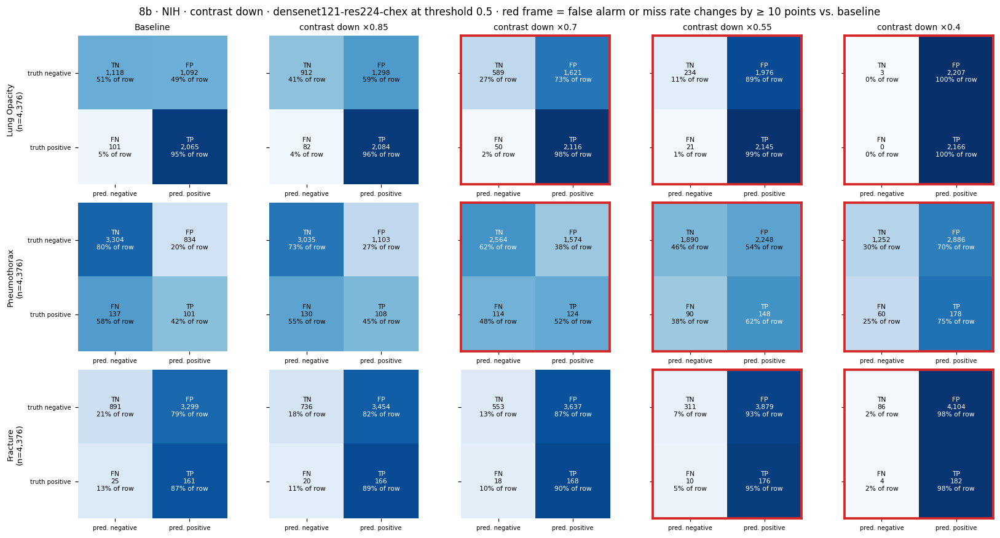

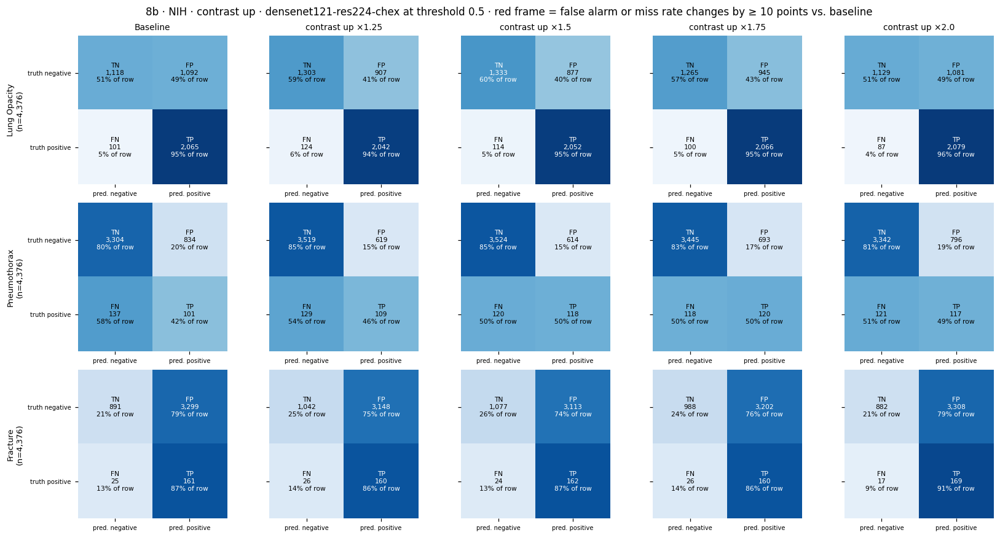

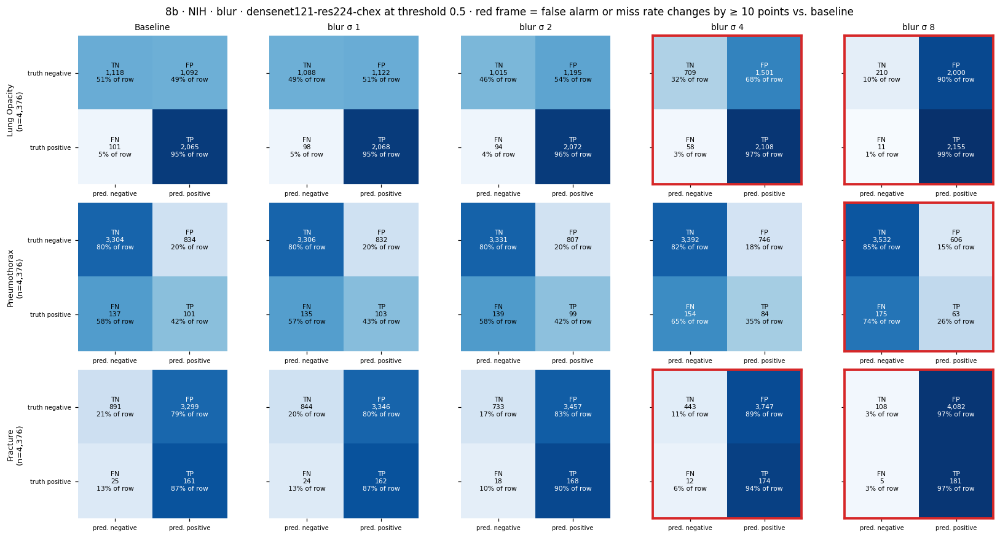

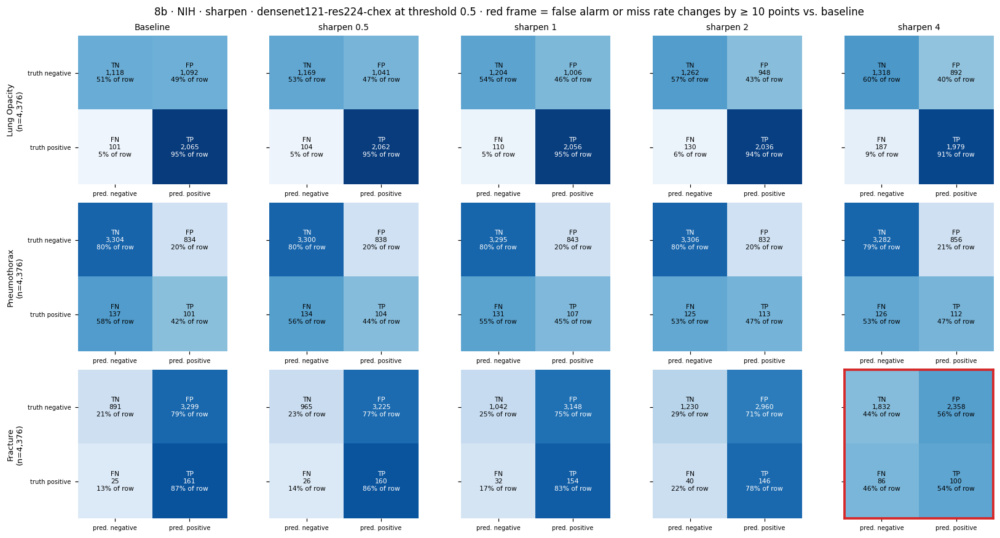

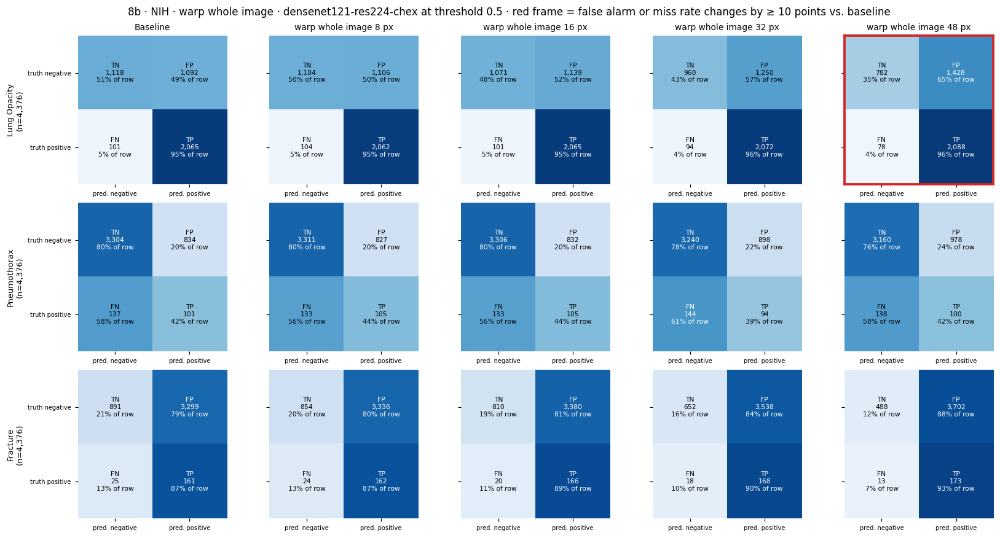

...

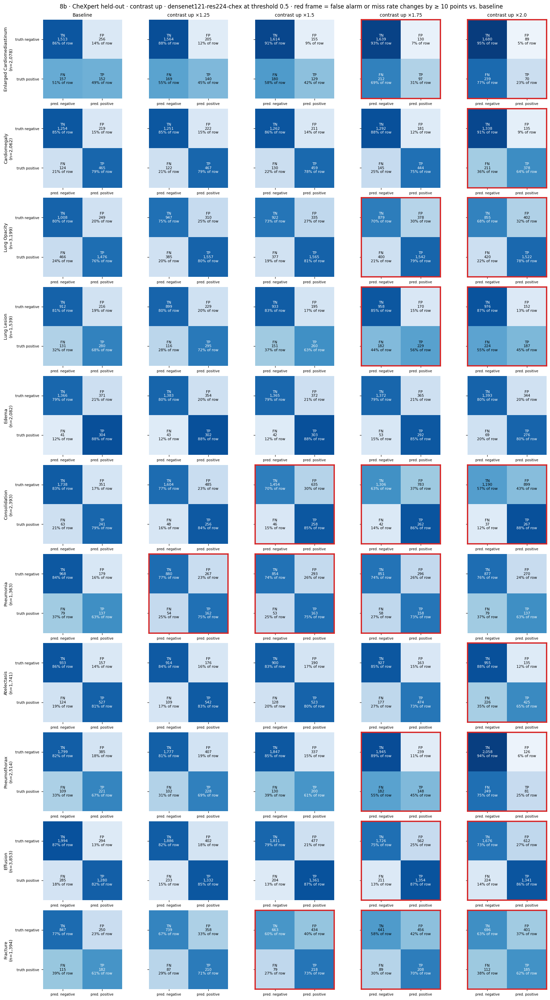

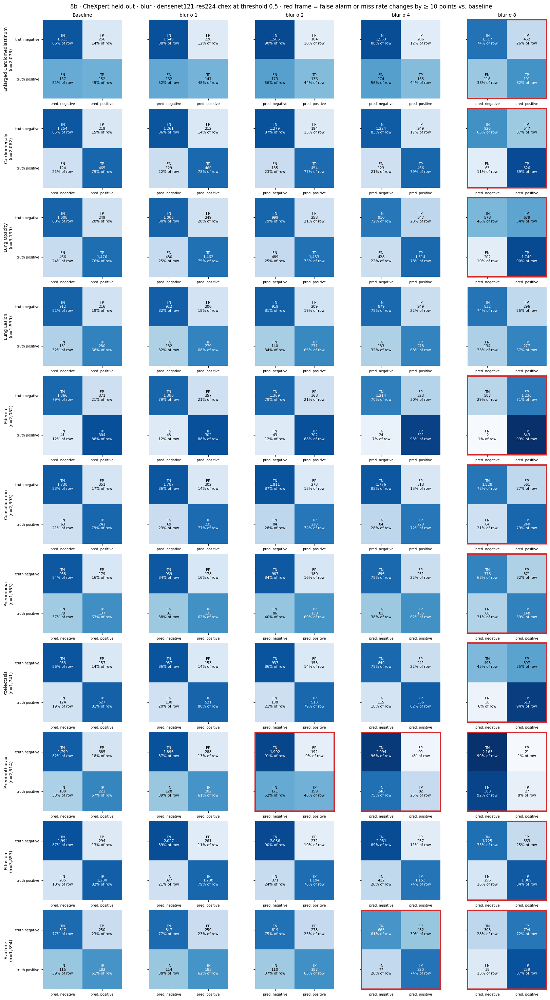

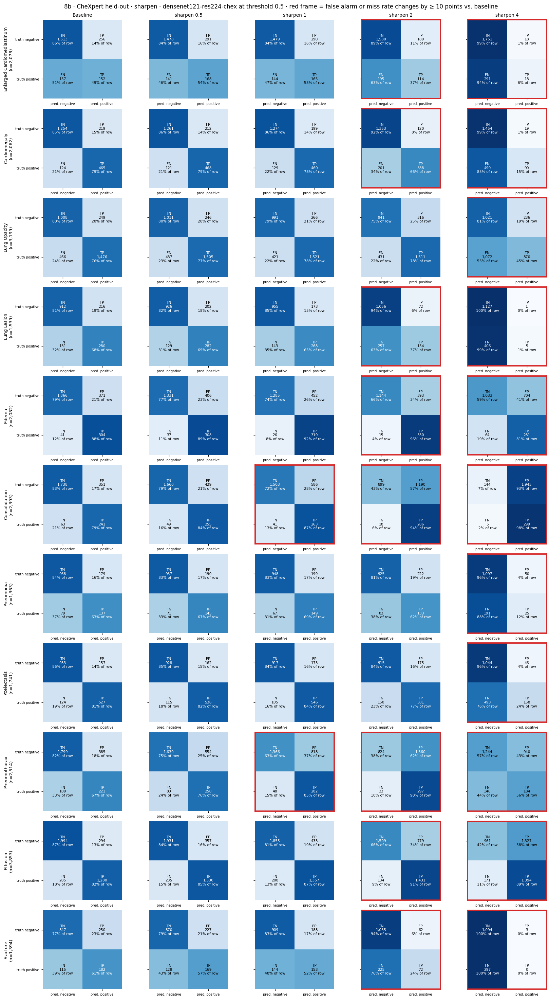

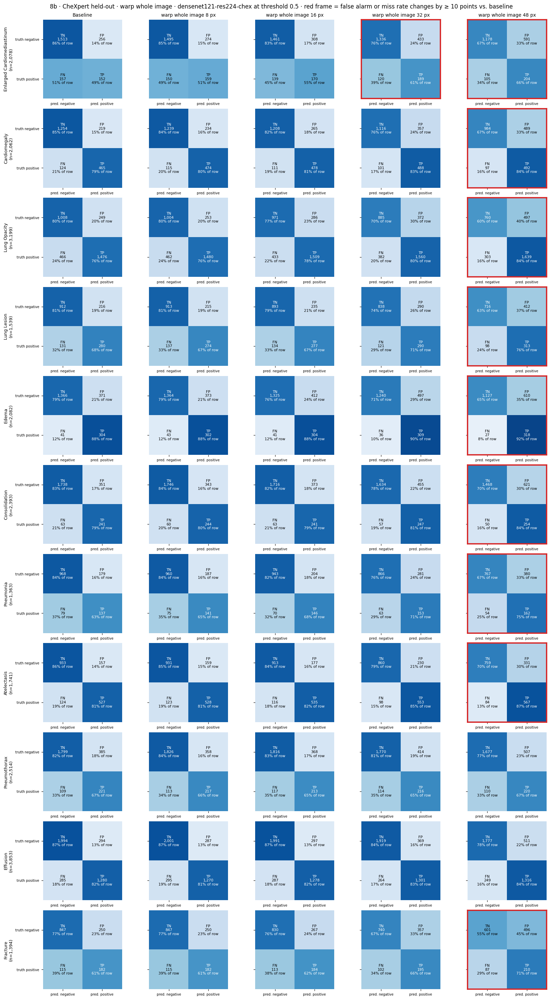

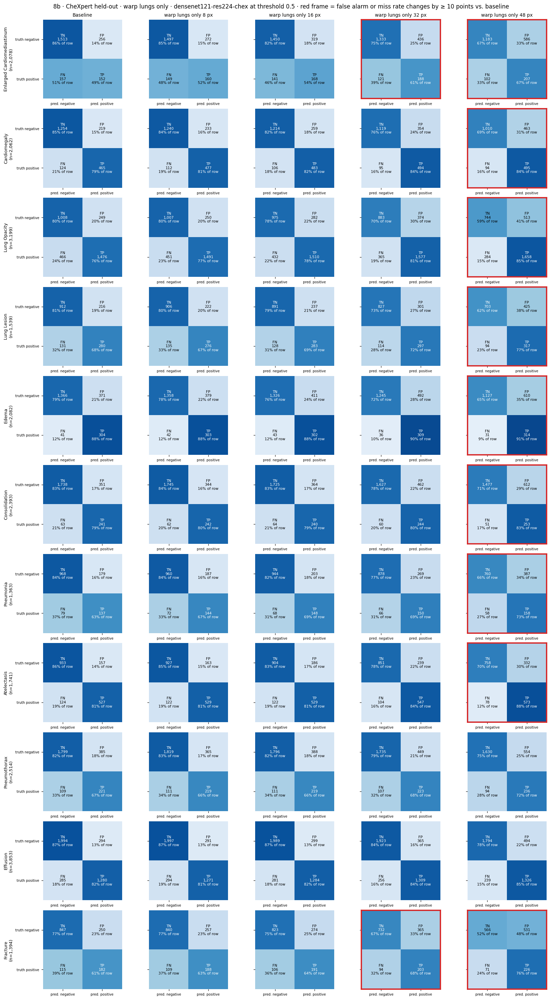

In [17]:
# ----- 8b · confusion grids, one figure per augmentation and test set -----------------------------------------------
for sn in RES8:
    L = long[long["test set"] == sn]
    outs_ = list(dict.fromkeys(L.output))
    for aug, (kind, ss, _) in AUGS.items():
        cols_ = ["Baseline"] + [label_of(aug, s) for s in ss]
        fig, axes = plt.subplots(len(outs_), len(cols_), figsize=(2.75 * len(cols_) + 1.2, 2.35 * len(outs_) + 0.8),
                                 layout="constrained", squeeze=False)
        for a, o in enumerate(outs_):
            base_r = L[(L.output == o) & (L.condition == "Baseline")].iloc[0]
            for b, cn in enumerate(cols_):
                r = L[(L.output == o) & (L.condition == cn)].iloc[0]
                C = np.array([[r.TN, r.FP], [r.FN, r.TP]])
                Rr = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
                ax = axes[a, b]
                ax.imshow(Rr, cmap="Blues", vmin=0, vmax=1)
                for (i, j), k in np.ndenumerate(C):
                    ax.text(j, i, f"{[['TN', 'FP'], ['FN', 'TP']][i][j]}\n{k:,}\n{Rr[i, j]:.0%} of row", ha="center",
                            va="center", fontsize=7, color="white" if Rr[i, j] > 0.6 else "black")
                ax.set_xticks([0, 1], ["pred. negative", "pred. positive"], fontsize=6.5)
                ax.set_yticks([0, 1], ["truth negative", "truth positive"] if b == 0 else ["", ""], fontsize=6.5)
                ax.grid(False)
                big = (abs(r["false alarm rate"] - base_r["false alarm rate"]) * 100 >= FRAME_PP and C[0].sum() >= MIN_POS) or \
                      (abs(r["miss rate"] - base_r["miss rate"]) * 100 >= FRAME_PP and C[1].sum() >= MIN_POS)
                if b > 0 and big:
                    for sp_ in ax.spines.values():
                        sp_.set_visible(True); sp_.set_edgecolor("#D62728"); sp_.set_linewidth(2.5)
                else:
                    ax.spines[:].set_visible(False)
                if a == 0:
                    ax.set_title(cn, fontsize=9)
                if b == 0:
                    ax.set_ylabel(f"{o}\n(n={int(C.sum()):,})", fontsize=8.5)
        fig.suptitle(f"8b · {sn} · {aug} · {WEIGHTS} at threshold {THRESHOLD} · red frame = false alarm or miss rate "
                     f"changes by ≥ {FRAME_PP} points vs. baseline", fontsize=11)
        save(fig, f"8b_confusion_{sn.replace(' ', '_')}_{aug.replace(' ', '_')}", dpi=85)

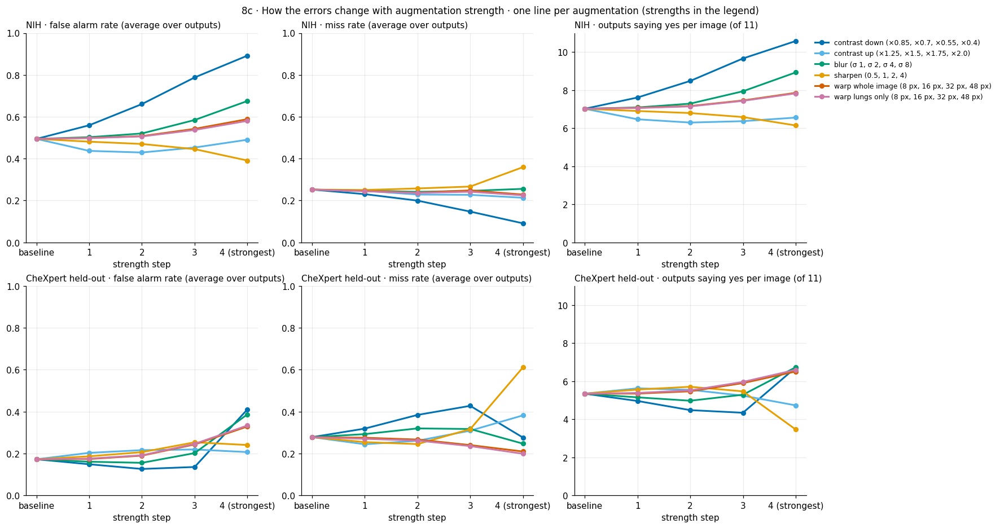

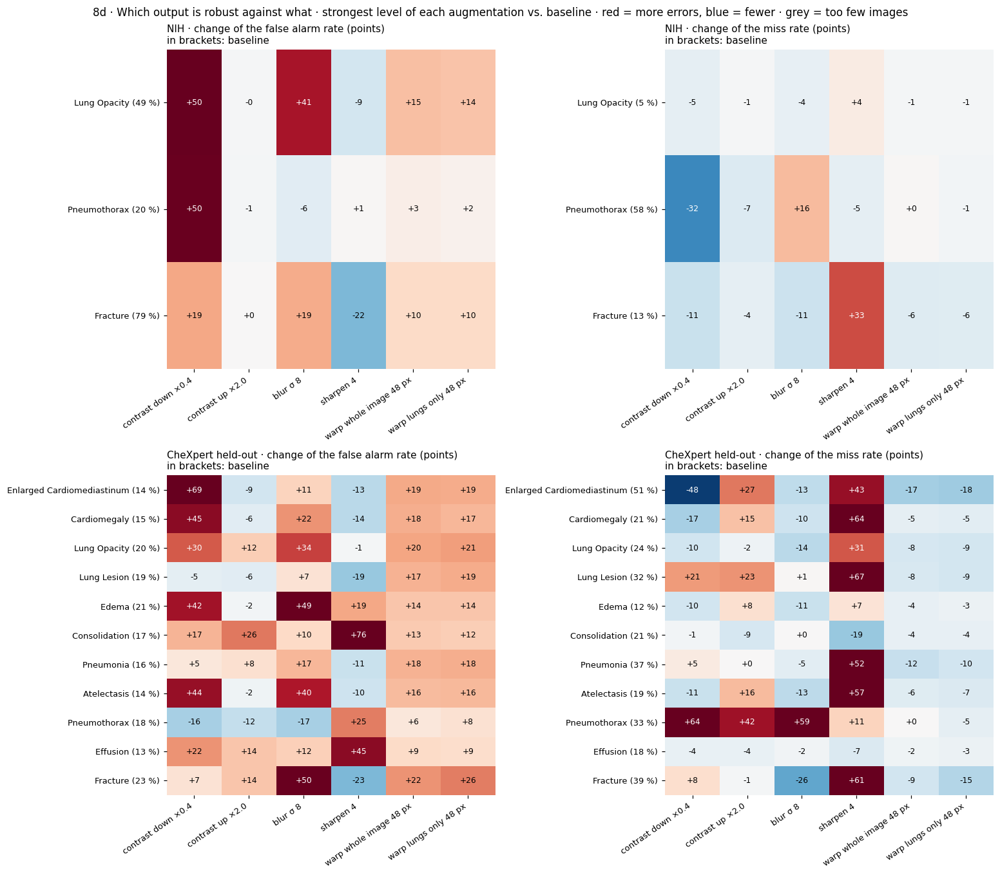

In [18]:
# ----- 8c · summary: rates vs. strength, all augmentations ------------------------------------------------------------
def avg_rates(L, cn):
    # average over outputs with enough negatives (false alarms) or positives (misses)
    b = L[L.condition == "Baseline"].set_index("output")
    ok_n = b.index[(b.TN + b.FP) >= MIN_POS]; ok_p = b.index[(b.FN + b.TP) >= MIN_POS]
    r = L[L.condition == cn]
    return r[r.output.isin(ok_n)]["false alarm rate"].mean(), r[r.output.isin(ok_p)]["miss rate"].mean()

fig, axes = plt.subplots(len(RES8), 3, figsize=(16, 4.2 * len(RES8)), layout="constrained", squeeze=False)
for a, (sn, (sub, S)) in enumerate(RES8.items()):
    L = long[long["test set"] == sn]
    for aug, (kind, ss, _) in AUGS.items():
        fa, mi, yes = [], [], []
        for cn in ["Baseline"] + [label_of(aug, s) for s in ss]:
            f_, m_ = avg_rates(L, cn)
            fa.append(f_); mi.append(m_); yes.append((S[cn] > THRESHOLD).sum(axis=1).mean())
        for ax, v in zip(axes[a], (fa, mi, yes)):
            ax.plot(range(5), v, "o-", color=C_AUG[aug], lw=2, ms=5, label=f"{aug} ({', '.join(AUGS[aug][2].format(s) for s in ss)})")
    for ax, t in zip(axes[a], ("false alarm rate (average over outputs)", "miss rate (average over outputs)",
                               f"outputs saying yes per image (of {len(OUTS)})")):
        ax.set_xticks(range(5), ["baseline", "1", "2", "3", "4 (strongest)"])
        ax.set_title(f"{sn} · {t}", loc="left", fontsize=10); ax.set_xlabel("strength step")
    axes[a, 0].set_ylim(0, 1); axes[a, 1].set_ylim(0, 1); axes[a, 2].set_ylim(0, len(OUTS))
axes[0, 2].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("8c · How the errors change with augmentation strength · one line per augmentation (strengths in the legend)",
             fontsize=11)
save(fig, "8c_summary_by_strength")

# ----- 8d · per output: change at the strongest level ---------------------------------------------------------------
fig, axes = plt.subplots(len(RES8), 2, figsize=(14, 0.42 * len(OUTS) * len(RES8) + 3), layout="constrained", squeeze=False)
for a, sn in enumerate(RES8):
    L = long[long["test set"] == sn]
    outs_ = list(dict.fromkeys(L.output))
    b = L[L.condition == "Baseline"].set_index("output")
    for c, (rate_name, nmin) in enumerate([("false alarm rate", b.TN + b.FP), ("miss rate", b.FN + b.TP)]):
        D = np.array([[(L[(L.output == o) & (L.condition == label_of(aug, AUGS[aug][1][-1]))][rate_name].iloc[0]
                        - b.loc[o, rate_name]) * 100 if nmin[o] >= MIN_POS else np.nan for aug in AUGS] for o in outs_])
        ax = axes[a, c]
        text_heat(ax, D, np.array([[("" if np.isnan(x) else f"{x:+.0f}") for x in r] for r in D]), 50, fontsize=8)
        ax.set_yticks(range(len(outs_)), [f"{o} ({100 * b.loc[o, rate_name]:.0f} %)" for o in outs_], fontsize=8.5)
        ax.set_xticks(range(len(AUGS)), [label_of(aug, AUGS[aug][1][-1]) for aug in AUGS], rotation=35, ha="right", fontsize=8.5)
        ax.set_title(f"{sn} · change of the {rate_name} (points)\nin brackets: baseline", loc="left", fontsize=10)
fig.suptitle("8d · Which output is robust against what · strongest level of each augmentation vs. baseline · "
             "red = more errors, blue = fewer · grey = too few images", fontsize=11)
save(fig, "8d_robustness_by_output")